# Ba neighboring-ion crosstalk
Analyze `ba_ionM1_2`, `ba_ion0_2`, and `ba_ion1_2` independently, then compare the three ions.
Each dataset has its own focused reference and saved zoom–angle–zoom–origin alignment. No image registration is performed between datasets.

The HDR rate is `max_exposure(max(R+G+B-dark, 0)/actual_exposure_seconds)` over exposures passing the adjustable signal and per-channel limits. No valid exposure means zero intensity and an invalid source index.

Run the function cells, settings, discovery, and alignment in order. Cached independent alignments are reused; a missing alignment requests two zoom windows and two point pairs on that dataset's own reference.

Figures display inline; the optional export cell saves the Ba matrix and height–radial maps to your chosen folder.

The common-y publication cells overlay all three channels without recentering, report all six directed cross-channel values, and export an editable SVG.


## Functions: input and independent alignment

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from scipy import ndimage
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "Analysis/gate_image_profiler.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from Analysis.gate_image_profiler import GateImageProfiler


def discover_dataset(folder):
    """Find this dataset's latest complete run and its own preceding reference."""
    folder = Path(folder)
    timestamp = lambda s: datetime.fromisoformat(s.replace("Z", "+00:00"))
    runs = []
    for path in sorted(folder.glob("signal_*/run_metadata.json")):
        metadata = json.loads(path.read_text())
        if metadata.get("status") == "complete" and (path.parent / "exposure_log.csv").is_file():
            runs.append((timestamp(metadata["started_utc"]), path.parent, metadata))
    if not runs:
        raise FileNotFoundError(f"No complete signal run in {folder}")
    started, run_dir, metadata = max(runs, key=lambda item: item[0])
    references = []
    for path in sorted(folder.glob("focused_*.json")):
        ref = json.loads(path.read_text())
        if ref.get("capture_kind") != "focused":
            continue
        image_path = folder / ref["raw_tiff"]
        received = timestamp(ref["frame_received_utc"])
        if image_path.is_file() and received <= started:
            references.append((received, image_path, ref))
    if not references:
        raise FileNotFoundError(f"No focused reference preceding {run_dir.name}")
    _, reference_path, reference_metadata = max(references, key=lambda item: item[0])
    table = pd.read_csv(run_dir / "exposure_log.csv").sort_values(
        ["height_index", "time_index", "exposure_index", "frame_index"]
    ).reset_index(drop=True)
    table.index.name = "image_index"
    table["path"] = table.filename.map(lambda name: run_dir / name)
    if len(table) != metadata["planned_frames"] or not len(table):
        raise ValueError(f"Incomplete exposure log: {run_dir}")
    missing = [str(p) for p in table.path if not p.is_file()]
    if missing:
        raise FileNotFoundError(f"Missing {len(missing)} frames, including {missing[0]}")
    return dict(name=folder.name, folder=folder, run_dir=run_dir, metadata=metadata,
                reference_path=reference_path, reference_metadata=reference_metadata,
                frames=table)


def load_dark_calibration(path):
    """The calibration is ONE spatial mean of R+G+B per exposure, not three means."""
    path = Path(path)
    with np.load(path, allow_pickle=False) as data:
        if data["exposure_unit"].item() != "ms":
            raise ValueError("Dark exposures must be in ms")
        if data["dark_count_definition"].item() != "mean over frames and pixels of B+G+R":
            raise ValueError("Unexpected dark-count units")
        exposure = data["actual_exposures_ms"].copy()
        counts = data["dark_counts"].copy()
        metadata = json.loads(data["metadata_json"].item())
    order = np.argsort(exposure)
    exposure, counts = exposure[order], counts[order]
    if (exposure.ndim != 1 or counts.shape != exposure.shape or len(exposure) < 2
            or not np.isfinite(exposure).all() or not np.isfinite(counts).all()
            or np.any(np.diff(exposure) <= 0)):
        raise ValueError("Invalid dark calibration exposure grid")
    return dict(path=path, exposure_ms=exposure, counts=counts, metadata=metadata)


def dark_at(dark, exposure_ms):
    exposure_ms = np.asarray(exposure_ms, dtype=float)
    grid = dark["exposure_ms"]
    if (not np.isfinite(exposure_ms).all() or np.any(exposure_ms < grid[0])
            or np.any(exposure_ms > grid[-1])):
        raise ValueError(f"Exposure outside dark calibration range [{grid[0]}, {grid[-1]}] ms")
    return np.interp(exposure_ms, grid, dark["counts"])


def rotate_pixels(image, angle_deg):
    """Rotate intensity values on the fixed full-size pixel grid, filling corners with zero.

    Selection zoom windows never slice the image. Coordinates are not rotated,
    rescaled, or expanded; only the intensity array receives this transform.
    """
    return ndimage.rotate(image, float(angle_deg), axes=(1, 0), reshape=False,
                          order=0, mode="constant", cval=0, prefilter=False)



def reference_signature(dataset):
    path = dataset["reference_path"]
    return dict(reference_name=path.name, reference_size=path.stat().st_size,
                reference_mtime_ns=path.stat().st_mtime_ns)


def save_alignment(dataset, record, directory):
    """Save only this dataset's alignment; no cross-dataset registration is used."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    record = dict(record, **reference_signature(dataset))
    (directory / f"{dataset['name']}.json").write_text(json.dumps(record, indent=2) + "\n")
    return record


def load_alignment(dataset, directory):
    path = Path(directory) / f"{dataset['name']}.json"
    if not path.is_file():
        return None
    record = json.loads(path.read_text())
    if any(record.get(key) != value for key, value in reference_signature(dataset).items()):
        return None
    return record


def select_alignment(dataset, directory, *, pixel_pitch_um=(5.3, 5.3), magnification=50.0):
    """Zoom box → angle pair → second zoom box → origin midpoint pair.

    The boxes set view limits only. All points keep full-image pixel coordinates.
    Rotate only the intensity on the original pixel grid; the second point pair
    sets its coordinate origin after rotation, without rotating the axes.
    """
    print(f"Aligning {dataset['name']}: {dataset['reference_path'].name}", flush=True)
    profiler = GateImageProfiler(pixel_pitch_um=pixel_pitch_um, magnification=magnification,
        ion_relative_to_wg_lens_um=0, wg_lens_relative_to_trench_um=0, interpolation_order=0)
    alignment = profiler.align_white_light(dataset["reference_path"], brightness_offset=0,
                                          select_rois=True)
    return save_alignment(dataset, dict(angle_deg=alignment.angle_deg,
        origin_px=list(alignment.trench_center_px), pixel_pitch_um=list(pixel_pitch_um),
        magnification=float(magnification),
        method="independent manual selection with two view-only zoom boxes",
        rotation_roi_px=alignment.rotation_roi_px.tolist(),
        rotation_points_px=alignment.rotation_points_px.tolist(),
        origin_roi_px=alignment.center_roi_px.tolist(),
        origin_points_px=alignment.trench_edges_px.tolist()), directory)



def image_axes(shape, alignment):
    ny, nx = shape[:2]
    dx, dy = np.asarray(alignment["pixel_pitch_um"], dtype=float) / alignment["magnification"]
    cx, cy = alignment["origin_px"]
    if not (0 <= cx < nx and 0 <= cy < ny and dx > 0 and dy > 0):
        raise ValueError("Invalid alignment origin or sample spacing")
    x, y = (np.arange(nx) - cx) * dx, (np.arange(ny) - cy) * dy
    extent = (x[0]-dx/2, x[-1]+dx/2, y[-1]+dy/2, y[0]-dy/2)
    return x, y, extent


def preview_references(datasets, alignments):
    fig, axes = plt.subplots(1, len(datasets), figsize=(5*len(datasets), 4), constrained_layout=True)
    for ax, (ion, dataset) in zip(np.atleast_1d(axes), datasets.items()):
        if ion not in alignments:
            ax.text(.5, .5, f"{dataset['name']}\nAlignment still needed", ha="center", transform=ax.transAxes)
            continue
        a = alignments[ion]
        image = rotate_pixels(tifffile.imread(dataset["reference_path"]), a["angle_deg"])
        _, _, extent = image_axes(image.shape, a)
        ax.imshow(image, origin="upper", extent=extent)
        ax.axhline(0, color="cyan", lw=.7)
        ax.axvline(0, color="cyan", lw=.7)
        ax.set(title=f"{dataset['name']}\nrotation = {a['angle_deg']:.4f} deg",
               xlabel="Axial x (um)", ylabel="Radial y (um)")
    plt.show()
    plt.close(fig)


## Functions: HDR, axial sampling, and neighboring matrices

In [2]:
def _fingerprint(dataset, alignment, dark, min_signal, max_rgb, excluded_exposures_ms=()):
    files = [dataset["run_dir"] / "exposure_log.csv", dark["path"], *dataset["frames"].path]
    payload = dict(version=1, alignment=alignment, min_signal=float(min_signal), max_rgb=float(max_rgb),
                   files=[(str(p), p.stat().st_size, p.stat().st_mtime_ns) for p in files])
    excluded = sorted(set(map(float, excluded_exposures_ms)))
    if excluded:
        payload["excluded_requested_exposure_ms"] = excluded
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


def process_dataset(dataset, alignment, dark, *, min_signal=5, max_rgb=220, cache_dir=None,
                    excluded_exposures_ms=()):
    """Stream RGB frames; dark-correct R+G+B and keep the highest valid counts/s."""
    if not np.isfinite(min_signal) or min_signal < 0 or not 0 < max_rgb <= 255:
        raise ValueError("Require min_signal >= 0 and 0 < max_rgb <= 255")
    for key in ("camera_id", "pixel_clock_mhz", "width", "height", "pixel_format"):
        if dark["metadata"][key] != dataset["metadata"][key]:
            raise ValueError(f"Dark calibration mismatch for {dataset['name']}: {key}")
    frames = dataset["frames"]
    excluded = np.asarray(excluded_exposures_ms, dtype=float)
    if excluded.ndim != 1 or not np.isfinite(excluded).all() or np.any(excluded <= 0):
        raise ValueError("Excluded nominal exposure times must be a finite positive list")
    excluded = sorted(set(excluded.tolist()))
    include_frame = np.ones(len(frames), dtype=bool)
    for exposure in excluded:
        include_frame &= ~np.isclose(frames.requested_exposure_ms, exposure, rtol=0, atol=1e-6)
    seconds = frames.actual_exposure_ms.to_numpy(dtype=float) / 1000
    if not np.isfinite(seconds).all() or np.any(seconds <= 0):
        raise ValueError("Actual exposure times must be positive and finite")
    dark_levels = dark_at(dark, frames.actual_exposure_ms)
    reference = rotate_pixels(tifffile.imread(dataset["reference_path"]), alignment["angle_deg"])
    x, y, extent = image_axes(reference.shape, alignment)
    reference_corrected = reference.sum(axis=-1, dtype=np.uint16).astype(np.float32)
    reference_corrected -= float(dark_at(dark, dataset["reference_metadata"]["exposure_ms"]))
    np.maximum(reference_corrected, 0, out=reference_corrected)
    fingerprint = _fingerprint(dataset, alignment, dark, min_signal, max_rgb, excluded)
    base = dict(dataset=dataset, alignment=alignment, x_um=x, y_um=y, extent=extent,
                reference_corrected=reference_corrected, min_signal=min_signal, max_rgb=max_rgb,
                excluded_exposures_ms=excluded)
    cache_path = None if cache_dir is None else Path(cache_dir) / f"{dataset['name']}.npz"
    if cache_path is not None and cache_path.is_file():
        with np.load(cache_path, allow_pickle=False) as cached:
            if cached["fingerprint"].item() == fingerprint:
                info = json.loads(cached["tables_json"].item())
                base.update(rate=cached["rate"].copy(), source=cached["source"].copy(),
                            heights_um=cached["heights_um"].copy())
                for key, records in info.items():
                    base[key] = pd.DataFrame(records)
                print(f"{dataset['name']}: reused processed cache", flush=True)
                return base
    groups = list(frames.groupby("height_index", sort=True).indices.items())
    shape = (len(groups), *reference.shape[:2])
    rate = np.zeros(shape, dtype=np.float32)
    source_dtype = np.int16 if len(frames) < 32767 else np.int32
    source = np.full(shape, -1, dtype=source_dtype)
    heights, summary, saturation, comparisons = [], [], [], []
    for slot, (height_id, indices) in enumerate(groups):
        indices = np.asarray(indices)
        physical_heights = frames.iloc[indices].target_height_um.to_numpy()
        if not np.allclose(physical_heights, physical_heights[0], rtol=0, atol=1e-5):
            raise ValueError("Inconsistent heights within an exposure group")
        height = float(physical_heights[0])
        heights.append(height)
        indices = indices[include_frame[indices]]
        if not len(indices):
            raise ValueError(f"All exposures excluded at height {height:g} um")
        candidates = []
        for index in indices[np.argsort(seconds[indices], kind="stable")]:
            raw = tifffile.imread(frames.iloc[index].path)
            if raw.shape != reference.shape or raw.dtype != np.uint8:
                raise ValueError(f"Unexpected RGB shape/dtype in {frames.iloc[index].path}")
            if np.isclose(frames.iloc[index].requested_exposure_ms, .2, rtol=0, atol=1e-6):
                maxima = raw.max(axis=(0, 1))
                saturation.append(dict(height_index=int(height_id), height_um=height,
                    max_R=int(maxima[0]), max_G=int(maxima[1]), max_B=int(maxima[2]),
                    saturated_pixels=int(np.count_nonzero(np.any(raw >= 255, axis=-1))),
                    all_channels_below_sat=bool((maxima < 255).all())))
            rgb = rotate_pixels(raw, alignment["angle_deg"])
            corrected = rgb.sum(axis=-1, dtype=np.uint16).astype(np.float32)
            corrected -= np.float32(dark_levels[index])
            np.maximum(corrected, 0, out=corrected)
            channel_peak = rgb.max(axis=-1)
            candidate_rate = corrected / seconds[index]
            valid = (corrected > min_signal) & (channel_peak < max_rgb) & np.isfinite(candidate_rate)
            take = valid & (candidate_rate > rate[slot])
            rate[slot, take] = candidate_rate[take]
            source[slot, take] = index
            candidates.append((int(index), corrected, channel_peak))
        valid = source[slot] >= 0
        record = dict(height_index=int(height_id), height_um=height,
            valid_pixels_pct=float(100*valid.mean()), peak_x_um=np.nan, peak_y_um=np.nan,
            peak_rate_counts_s=np.nan, peak_exposure_ms=np.nan,
            peak_requested_exposure_ms=np.nan, peak_uses_0p2_ms=False)
        if valid.any():
            row, col = np.unravel_index(np.argmax(rate[slot]), rate[slot].shape)
            chosen = int(source[slot, row, col])
            nominal = float(frames.iloc[chosen].requested_exposure_ms)
            record.update(peak_x_um=float(x[col]), peak_y_um=float(y[row]),
                peak_rate_counts_s=float(rate[slot, row, col]),
                peak_exposure_ms=float(seconds[chosen]*1000), peak_requested_exposure_ms=nominal,
                peak_uses_0p2_ms=bool(np.isclose(nominal, .2, rtol=0, atol=1e-6)))
            for index, counts_image, channel_image in candidates:
                counts, channel = float(counts_image[row, col]), int(channel_image[row, col])
                comparisons.append(dict(height_index=int(height_id), height_um=height,
                    requested_exposure_ms=float(frames.iloc[index].requested_exposure_ms),
                    actual_exposure_ms=float(seconds[index]*1000), corrected_counts=counts,
                    max_rgb_channel=channel, rate_counts_s=counts/seconds[index],
                    passes_thresholds=bool(counts > min_signal and channel < max_rgb),
                    selected_at_peak=bool(index == chosen)))
        summary.append(record)
        del candidates
        if slot == 0 or (slot+1) % 5 == 0 or slot+1 == len(groups):
            print(f"{dataset['name']}: {slot+1}/{len(groups)} heights", flush=True)
    base.update(rate=rate, source=source, heights_um=np.asarray(heights),
                summary=pd.DataFrame(summary), saturation=pd.DataFrame(saturation),
                comparisons=pd.DataFrame(comparisons))
    if cache_path is not None:
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        info = {key: json.loads(base[key].to_json(orient="records"))
                for key in ("summary", "saturation", "comparisons")}
        np.savez_compressed(cache_path, fingerprint=fingerprint, rate=rate, source=source,
                           heights_um=base["heights_um"], tables_json=json.dumps(info))
    return base


def height_slot(result, height_um, tolerance=1e-4):
    matches = np.flatnonzero(np.isclose(result["heights_um"], height_um, rtol=0, atol=tolerance))
    if len(matches) != 1:
        raise ValueError(f"Height {height_um:g} um not uniquely available in {result['dataset']['name']}")
    return int(matches[0])


def axial_profile(result, slot, y_um=None):
    """Use the brightest-pixel row or the nearest measured row to a requested y."""
    image = result["rate"][slot]
    valid = (result["source"][slot] >= 0) & np.isfinite(image) & (image > 0)
    x, y = result["x_um"], result["y_um"]
    if y_um is None:
        if not valid.any():
            return np.full(len(x), np.nan), np.nan, np.nan, np.nan
        row, _ = np.unravel_index(np.argmax(np.where(valid, image, -np.inf)), image.shape)
        profile = np.where(valid[row], image[row], np.nan)
        selected_y = float(y[row])
    else:
        if not np.isfinite(y_um) or not y[0] <= y_um <= y[-1]:
            raise ValueError(f"Requested y={y_um} outside {result['dataset']['name']} image")
        row = int(np.argmin(np.abs(y-y_um)))
        profile = np.where(valid[row], image[row], np.nan)
        selected_y = float(y[row])
    if not np.isfinite(profile).any():
        return profile, np.nan, selected_y, np.nan
    col = int(np.nanargmax(profile))
    return profile, float(x[col]), selected_y, float(profile[col])



def sample_linear(x, values, target):
    """Interpolate linear rate between adjacent valid pixels, without gap bridging."""
    x, values = np.asarray(x), np.asarray(values)
    if not np.isfinite(target) or not x[0] <= target <= x[-1]:
        return np.nan
    right = int(np.searchsorted(x, target))
    if right < len(x) and np.isclose(x[right], target, rtol=0, atol=1e-12):
        value = values[right]
    elif right == 0 or right == len(x) or not np.isfinite(values[[right-1, right]]).all():
        return np.nan
    else:
        fraction = (target-x[right-1])/(x[right]-x[right-1])
        value = (1-fraction)*values[right-1]+fraction*values[right]
    return float(value) if np.isfinite(value) and value > 0 else np.nan


def ratio_db(value, reference):
    return float(10*np.log10(value/reference)) if (np.isfinite(value) and value > 0
        and np.isfinite(reference) and reference > 0) else np.nan


def crosstalk_by_height(result, offset_um=5, y_um=None):
    if not np.isfinite(offset_um) or offset_um <= 0:
        raise ValueError("Offset must be positive")
    records = []
    for slot, height in enumerate(result["heights_um"]):
        profile, peak_x, peak_y, peak = axial_profile(result, slot, y_um)
        record = dict(height_um=float(height), peak_x_um=peak_x, sample_y_um=peak_y,
                      peak_rate_counts_s=peak)
        for name, sign in (("minus", -1), ("plus", 1)):
            target = peak_x+sign*offset_um
            rate = sample_linear(result["x_um"], profile, target)
            record[f"sample_x_{name}_um"] = target
            record[f"crosstalk_{name}_db"] = ratio_db(rate, peak)
        records.append(record)
    return pd.DataFrame(records)


def neighboring_matrices(results, y_um=None, pitch_um=5):
    """Use only each driven image's own peak, row, and nearest measured pixels.

    Rows are measured-ion locations; columns are driven ions. For drive i and
    measured location j, sample x_peak_i + (j-i)*pitch_um in dataset i only.
    Normalize to that same dataset's peak on the same row and at the same height.
    """
    if not np.isfinite(pitch_um) or pitch_um <= 0:
        raise ValueError("Ion pitch must be positive and finite")
    ions = sorted(results)
    common = sorted(set.intersection(*(set(np.round(results[i]["heights_um"], 6)) for i in ions)))
    if not common:
        raise ValueError("The datasets have no common physical heights")
    matrices = np.full((len(common), len(ions), len(ions)), np.nan)
    records, positions = [], []
    for hslot, height in enumerate(common):
        for column, driven in enumerate(ions):
            result = results[driven]
            profile, own_x, own_y, own_peak = axial_profile(result, height_slot(result, height), y_um)
            positions.append(dict(height_um=height, ion=driven, peak_x_um=own_x,
                                  peak_y_um=own_y, peak_rate_counts_s=own_peak))
            x = result["x_um"]
            for row, measured in enumerate(ions):
                offset = (measured-driven)*pitch_um
                target_x = own_x+offset
                actual_x, rate = np.nan, np.nan
                if np.isfinite(target_x) and x[0] <= target_x <= x[-1]:
                    index = int(np.argmin(np.abs(x-target_x)))
                    actual_x = float(x[index])
                    if np.isfinite(profile[index]) and profile[index] > 0:
                        rate = float(profile[index])
                value = ratio_db(rate, own_peak)
                matrices[hslot, row, column] = value
                records.append(dict(height_um=height, measured_ion=measured, driven_ion=driven,
                    driven_peak_x_um=own_x, requested_offset_um=offset,
                    requested_x_um=target_x, sample_x_um=actual_x,
                    actual_offset_um=actual_x-own_x, sample_y_um=own_y,
                    rate_counts_s=rate, reference_rate_counts_s=own_peak,
                    crosstalk_db=value, sampling_mode="driven_peak_nearest_pixel"))
    return dict(ions=ions, heights_um=np.asarray(common), db=matrices,
                table=pd.DataFrame(records), peak_positions=pd.DataFrame(positions),
                mode="driven_peak_nearest_pixel")


## Functions: plots

In [3]:
def plot_hdr(result, heights_um, db_floor=-40):
    frames = result["dataset"]["frames"]
    nominal = frames.requested_exposure_ms.to_numpy()
    from matplotlib.colors import ListedColormap
    all_levels = np.sort(np.unique(nominal))
    excluded = result.get("excluded_exposures_ms", [])
    eligible = np.ones(len(all_levels), dtype=bool)
    for exposure in excluded:
        eligible &= ~np.isclose(all_levels, exposure, rtol=0, atol=1e-6)
    levels = all_levels[eligible]
    if not len(levels):
        raise ValueError("No eligible exposure levels to plot")
    # Preserve the original exposure colors across ions, while hiding excluded levels.
    base_colors = plt.get_cmap("viridis", len(all_levels))(np.arange(len(all_levels)))
    exposure_cmap = ListedColormap(base_colors[eligible])
    exposure_cmap.set_bad("lightgray")
    norm = BoundaryNorm(np.arange(len(levels)+1)-.5, len(levels))
    cmap = plt.get_cmap("inferno").copy()
    cmap.set_bad("lightgray")
    heights_um = result["heights_um"] if heights_um is None else heights_um
    for height in heights_um:
        slot = height_slot(result, height)
        profile, px, py, peak = axial_profile(result, slot)
        if not np.isfinite(peak):
            continue
        valid = result["source"][slot] >= 0
        image = np.full(valid.shape, np.nan, dtype=np.float32)
        image[valid] = 10*np.log10(result["rate"][slot, valid]/peak)
        category = np.zeros(valid.shape, dtype=np.int16)
        category[valid] = np.searchsorted(levels, nominal[result["source"][slot, valid]])
        fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
        fig.suptitle(f"{result['dataset']['name']} | height = {height:g} um")
        im = axes[0].imshow(image, origin="upper", extent=result["extent"], cmap=cmap,
                            vmin=db_floor, vmax=0, interpolation="nearest")
        axes[0].plot(px, py, "+", color="cyan")
        axes[0].axhline(py, color="cyan", ls="--", lw=.7)
        axes[0].set(title="HDR rate", xlabel="Axial x (um)", ylabel="Radial y (um)")
        fig.colorbar(im, ax=axes[0], label="Intensity / peak (dB)")
        axes[1].plot(result["x_um"], 10*np.log10(profile/peak), lw=1)
        axes[1].plot(px, 0, "ro", ms=4)
        axes[1].set(title=f"Axial row at y={py:.3f} um", xlabel="Axial x (um)",
                    ylabel="Intensity / peak (dB)", ylim=(db_floor, 1))
        axes[1].grid(alpha=.3)
        im = axes[2].imshow(np.ma.array(category, mask=~valid), origin="upper",
            extent=result["extent"], cmap=exposure_cmap, norm=norm, interpolation="nearest")
        cb = fig.colorbar(im, ax=axes[2], ticks=np.arange(len(levels)))
        cb.set_ticklabels([f"{t:g}" for t in levels])
        cb.set_label("Selected exposure (ms; nominal)")
        axes[2].set(title="Exposure selection", xlabel="Axial x (um)", ylabel="Radial y (um)")
        plt.show()
        plt.close(fig)


def plot_crosstalk_scan(tables, offset_um=5):
    fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
    for color, (ion, table) in zip(plt.get_cmap("tab10").colors, sorted(tables.items())):
        for side, sign, style in (("minus", "-", "-"), ("plus", "+", "--")):
            ax.plot(table.height_um, table[f"crosstalk_{side}_db"], style, color=color,
                    marker="o", ms=3, label=f"Ion {ion:+d}: x_peak {sign} {offset_um:g} um")
    ax.set(xlabel="Height above chip (um)", ylabel="Crosstalk / row peak (dB)",
           title="Axial crosstalk versus height")
    ax.grid(alpha=.3)
    ax.legend(fontsize=9, ncol=2)
    plt.show()
    plt.close(fig)


def plot_neighbor_matrix(scan, height_um, db_floor=-40, font_family="Arial", font_size=16, show=True):
    indices = np.flatnonzero(np.isclose(scan["heights_um"], height_um, rtol=0, atol=1e-4))
    if len(indices) != 1:
        raise ValueError("Select a height common to all datasets")
    values = scan["db"][int(indices[0])]
    labels = [rf"Ion$_{{{int(i)}}}$" for i in scan["ions"]]
    with plt.rc_context(_publication_style(font_family, font_size)):
        cmap = plt.get_cmap("inferno").copy()
        cmap.set_bad("lightgray")
        fig, ax = plt.subplots(figsize=(7.2, 6), constrained_layout=True)
        im = ax.imshow(values, vmin=db_floor, vmax=0, cmap=cmap, interpolation="nearest")
        ax.set(xticks=np.arange(len(labels)), xticklabels=labels,
               yticks=np.arange(len(labels)), yticklabels=labels,
               xlabel="Driven ion location index", ylabel="Measured ion location index",
               title=f"Crosstalk matrix | height = {height_um:g} µm")
        for row, col in np.ndindex(values.shape):
            value = values[row, col]
            text = f"{value:.1f}" if np.isfinite(value) else "N/A"
            ax.text(col, row, text, ha="center", va="center", fontsize=font_size,
                    color="black" if np.isfinite(value) and value > -8 else "white")
        fig.colorbar(im, ax=ax, label="Crosstalk (dB)")
        if show:
            plt.show()
            plt.close(fig)
            return None
        return fig


def plot_neighbor_scan(scan):
    fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
    for driven in scan["ions"]:
        for measured in scan["ions"]:
            if abs(driven-measured) != 1:
                continue
            table = scan["table"]
            subset = table[(table.driven_ion == driven) & (table.measured_ion == measured)]
            ax.plot(subset.height_um, subset.crosstalk_db, marker="o", ms=3,
                    label=f"Drive {driven:+d} -> measure {measured:+d}")
    ax.set(xlabel="Height above chip (um)", ylabel="Neighbor crosstalk (dB)",
           title="Nearest-neighbor crosstalk versus height")
    ax.grid(alpha=.3)
    ax.legend(fontsize=9, ncol=2)
    plt.show()
    plt.close(fig)


def plot_matrix_grid(scan, db_floor=-40, columns=4):
    rows = int(np.ceil(len(scan["heights_um"])/columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3.1*columns, 2.8*rows),
                             constrained_layout=True, squeeze=False)
    cmap = plt.get_cmap("inferno").copy()
    cmap.set_bad("lightgray")
    labels = [f"{i:+d}" for i in scan["ions"]]
    for slot, ax in enumerate(axes.flat):
        if slot >= len(scan["heights_um"]):
            ax.set_visible(False)
            continue
        values = scan["db"][slot]
        im = ax.imshow(values, vmin=db_floor, vmax=0, cmap=cmap, interpolation="nearest")
        ax.set(title=f"{scan['heights_um'][slot]:g} um", xticks=np.arange(len(labels)),
               xticklabels=labels, yticks=np.arange(len(labels)), yticklabels=labels,
               xlabel="Driven ion", ylabel="Measured ion")
        for row, col in np.ndindex(values.shape):
            value = values[row, col]
            ax.text(col, row, f"{value:.1f}" if np.isfinite(value) else "N/A",
                ha="center", va="center", fontsize=8,
                color="black" if np.isfinite(value) and value > -8 else "white")
    fig.colorbar(im, ax=[a for a in axes.flat if a.get_visible()], shrink=.7,
                 label="Intensity / driven-ion peak (dB)")
    plt.show()
    plt.close(fig)


## Functions: 75 µm reference slices and height–radial maps

In [4]:
def _sample_profile_grid(x, cube, valid, targets):
    """Use the closest measured axial pixel, preserving invalid samples."""
    inside = np.isfinite(targets) & (targets >= x[0]) & (targets <= x[-1])
    right = np.clip(np.searchsorted(x, targets), 0, len(x)-1)
    left = np.maximum(right-1, 0)
    nearest = np.where(np.abs(targets-x[left]) <= np.abs(x[right]-targets), left, right)
    take = lambda array: np.take_along_axis(array, nearest[..., None], axis=2)[..., 0]
    good = inside & take(valid)
    values = np.where(good & (take(cube) > 0), take(cube), np.nan)
    return values, nearest, nearest, np.zeros(targets.shape)


def sample_nearest(x, values, target):
    if not np.isfinite(target) or not x[0] <= target <= x[-1]:
        return np.nan, np.nan
    index = int(np.argmin(np.abs(x-target)))
    value = values[index]
    return (float(value), float(x[index])) if np.isfinite(value) and value > 0 else (np.nan, float(x[index]))


def _uniform_window(center, half_range, step):
    if not np.isfinite(step) or step <= 0:
        raise ValueError("Sampling steps must be finite and positive")
    intervals = 2*half_range/step
    if not np.isclose(intervals, round(intervals), rtol=0, atol=1e-9):
        raise ValueError("The full sampling window must be an integer multiple of its step")
    return center-half_range+np.arange(int(round(intervals))+1)*step


def analyze_reference_windows(results, offsets_by_ion, reference_height_um=75.,
                              height_half_range_um=10., radial_half_range_um=5.,
                              peak_search_half_width_um=None, radial_step_um=None,
                              height_step_um=None):
    """Use nearest measured heights, radial rows, and axial pixels; no interpolation.

    Nominal target coordinates and actual sampled coordinates are both recorded.
    None sampling steps preserve the corresponding native grid.
    """
    if set(results) != set(offsets_by_ion):
        raise ValueError("Specify two signed offsets for every ion")
    if (not np.isfinite([reference_height_um, height_half_range_um, radial_half_range_um]).all()
            or height_half_range_um <= 0 or radial_half_range_um <= 0):
        raise ValueError("Reference height and positive finite window ranges are required")
    if peak_search_half_width_um is not None and (
            not np.isfinite(peak_search_half_width_um) or peak_search_half_width_um <= 0):
        raise ValueError("Optional axial peak-search half-width must be positive")
    maps, anchors, baseline_records = {}, [], []
    for ion, result in sorted(results.items()):
        offsets = np.asarray(offsets_by_ion[ion], dtype=float)
        if offsets.ndim != 1 or len(offsets) != 2 or not np.isfinite(offsets).all() or np.any(offsets == 0):
            raise ValueError("Each ion needs two finite nonzero axial offsets")
        ref_slot = height_slot(result, reference_height_um)
        reference_profile, x0, y0, reference_peak = axial_profile(result, ref_slot)
        if not np.isfinite(reference_peak):
            raise ValueError(f"No valid reference peak for ion {ion}")
        x, y, heights = result["x_um"], result["y_um"], result["heights_um"]
        if (heights.min() > reference_height_um-height_half_range_um+1e-4
                or heights.max() < reference_height_um+height_half_range_um-1e-4):
            raise ValueError(f"Ion {ion}: requested height window is not covered")
        if y0-radial_half_range_um < y[0] or y0+radial_half_range_um > y[-1]:
            raise ValueError(f"Ion {ion}: requested radial window extends outside the image")
        if height_step_um is None:
            h_indices = np.flatnonzero(np.abs(heights-reference_height_um) <= height_half_range_um+1e-4)
            h_indices = h_indices[np.argsort(heights[h_indices])]
        else:
            requested_heights = _uniform_window(reference_height_um, height_half_range_um, height_step_um)
            h_indices = np.asarray([int(np.argmin(np.abs(heights-h))) for h in requested_heights])
        if radial_step_um is None:
            lower = np.flatnonzero(np.abs(y-y0) <= radial_half_range_um+1e-10)
            upper, radial_y = lower.copy(), y[lower]
            radial_weight = np.zeros(len(lower))
        else:
            radial_y = _uniform_window(y0, radial_half_range_um, radial_step_um)
            lower = np.asarray([int(np.argmin(np.abs(y-target))) for target in radial_y])
            upper = lower.copy()
            radial_weight = np.zeros(len(radial_y))
        if len(h_indices) < 2 or len(radial_y) < 2:
            raise ValueError("At least two heights and radial coordinates are needed")
        cols = np.arange(len(x))
        # Directly take the selected measured rows: no blending or interpolation.
        cube = result["rate"][np.ix_(h_indices, lower, cols)]
        low_sources = result["source"][np.ix_(h_indices, lower, cols)]
        high_sources = low_sources  # Same selected pixel in both provenance slots.
        valid = (low_sources >= 0) & np.isfinite(cube) & (cube > 0)
        search = valid.copy()
        if peak_search_half_width_um is not None:
            search &= (np.abs(x-x0) <= peak_search_half_width_um)[None, None, :]
        found_peak = search.any(axis=2)
        peak_col = np.argmax(np.where(search, cube, -np.inf), axis=2)
        take = lambda array, index: np.take_along_axis(array, index[..., None], axis=2)[..., 0]
        central = np.where(found_peak, take(cube, peak_col), np.nan)
        peak_x = np.where(found_peak, x[peak_col], np.nan)
        peak_sources = np.stack([take(low_sources, peak_col), take(high_sources, peak_col)], axis=-1)
        peak_sources[~found_peak] = -1
        ratios, db_maps, numerator_maps, neighbor_sources, weights, sampled_x = [], [], [], [], [], []
        for offset in offsets:
            numerator, left, right, fraction = _sample_profile_grid(x, cube, valid, peak_x+offset)
            ratio = np.divide(numerator, central, out=np.full(central.shape, np.nan),
                              where=np.isfinite(central) & (central > 0))
            if peak_search_half_width_um is None and np.any(ratio[np.isfinite(ratio)] > 1+1e-6):
                raise AssertionError("Neighbor rate exceeds the full-slice maximum")
            positive = np.isfinite(ratio) & (ratio > 0)
            db = np.full(ratio.shape, np.nan)
            db[positive] = 10*np.log10(ratio[positive])
            # Provenance axes: [radial lower/upper, axial left/right].
            pairs = np.stack([
                np.stack([take(low_sources, left), take(low_sources, right)], axis=-1),
                np.stack([take(high_sources, left), take(high_sources, right)], axis=-1)], axis=-2)
            pairs[~positive] = -1
            ratios.append(ratio); db_maps.append(db); numerator_maps.append(numerator)
            neighbor_sources.append(pairs); weights.append(fraction)
            sampled_x.append(np.where(positive, x[left], np.nan))
        ref_row = int(np.argmin(np.abs(y-y0)))
        ref_col = int(np.argmin(np.abs(x-x0)))
        ref_source = int(result["source"][ref_slot, ref_row, ref_col])
        frames = result["dataset"]["frames"]
        anchors.append(dict(ion=int(ion), dataset=result["dataset"]["name"],
            reference_height_um=reference_height_um, peak_x_um=x0, peak_y_um=y0,
            reference_peak_counts_s=reference_peak,
            reference_exposure_ms=float(frames.iloc[ref_source].actual_exposure_ms),
            reference_nominal_exposure_ms=float(frames.iloc[ref_source].requested_exposure_ms),
            native_radial_step_um=float(np.median(np.diff(y))), radial_samples=len(radial_y),
            radial_sample_step_um=float(np.median(np.diff(radial_y))),
            height_sample_step_um=float(height_step_um if height_step_um is not None else np.median(np.diff(heights[h_indices])))))
        for offset in offsets:
            numerator, actual_x = sample_nearest(x, reference_profile, x0+offset)
            baseline_records.append(dict(ion=int(ion), offset_um=float(offset), height_um=reference_height_um,
                peak_x_um=x0, peak_y_um=y0, target_x_um=x0+offset, sample_x_um=actual_x,
                actual_offset_um=actual_x-x0, central_rate_counts_s=reference_peak,
                neighbor_rate_counts_s=numerator,
                crosstalk_linear=numerator/reference_peak if np.isfinite(numerator) else np.nan,
                crosstalk_db=ratio_db(numerator, reference_peak)))
        maps[ion] = dict(ion=int(ion), offsets_um=offsets,
            heights_um=(heights[h_indices] if height_step_um is None else requested_heights),
            sampled_heights_um=heights[h_indices], sampled_radial_y_um=y[lower],
            sampled_neighbor_x_um=np.asarray(sampled_x),
            radial_y_um=radial_y, radial_offset_um=radial_y-y0,
            reference_x_um=x0, reference_y_um=y0, reference_height_um=reference_height_um,
            reference_profile=reference_profile, x_um=x, reference_peak_counts_s=reference_peak,
            central_rate=central, peak_x_um=peak_x, peak_sources=peak_sources,
            radial_interpolation_fraction=np.broadcast_to(radial_weight, central.shape).copy(),
            numerator_rate=np.asarray(numerator_maps), ratio=np.asarray(ratios), db=np.asarray(db_maps),
            neighbor_sources=np.asarray(neighbor_sources), interpolation_fraction=np.asarray(weights),
            frame_nominal_ms=frames.requested_exposure_ms.to_numpy(dtype=float),
            frame_actual_ms=frames.actual_exposure_ms.to_numpy(dtype=float))
    return dict(maps=maps, anchors=pd.DataFrame(anchors), baseline=pd.DataFrame(baseline_records),
        settings=dict(reference_height_um=float(reference_height_um),
            height_half_range_um=float(height_half_range_um), radial_half_range_um=float(radial_half_range_um),
            radial_step_um=radial_step_um, height_step_um=height_step_um,
            peak_search_half_width_um=peak_search_half_width_um,
            peak_tracking="maximum valid HDR rate on each nearest measured radial row and height plane",
            normalization="central peak on the same height and radial slice",
            interpolation="none; nearest measured height, radial row, and axial pixel",
            offsets_by_ion={str(i): list(map(float, offsets_by_ion[i])) for i in sorted(offsets_by_ion)}))


def export_reference_windows(analysis, results, directory, color_limits_db=(-40., 0.)):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    analysis["anchors"].to_csv(directory/"reference_peaks_75um.csv", index=False)
    analysis["baseline"].to_csv(directory/"reference_crosstalk_75um.csv", index=False)
    long_tables, diagnostics = [], []
    for ion, scan in sorted(analysis["maps"].items()):
        height, radial = np.meshgrid(scan["heights_um"], scan["radial_offset_um"], indexing="ij")
        actual_y = radial+scan["reference_y_um"]
        lookup = lambda indices, values: np.where(indices >= 0, values[np.clip(indices, 0, len(values)-1)], np.nan)
        peak_exposure = lookup(scan["peak_sources"], scan["frame_actual_ms"])
        for index, offset in enumerate(scan["offsets_um"]):
            sources = scan["neighbor_sources"][index]
            values = dict(ion=np.full(height.size, ion), offset_um=np.full(height.size, offset),
                height_um=height.ravel(), radial_offset_um=radial.ravel(), radial_y_um=actual_y.ravel(),
                sampled_height_um=np.broadcast_to(scan["sampled_heights_um"][:, None], height.shape).ravel(),
                sampled_radial_y_um=np.broadcast_to(scan["sampled_radial_y_um"], height.shape).ravel(),
                sampled_neighbor_x_um=scan["sampled_neighbor_x_um"][index].ravel(),
                axial_peak_x_um=scan["peak_x_um"].ravel(),
                central_rate_counts_s=scan["central_rate"].ravel(),
                neighbor_rate_counts_s=scan["numerator_rate"][index].ravel(),
                crosstalk_linear=scan["ratio"][index].ravel(), crosstalk_db=scan["db"][index].ravel(),
                radial_interpolation_fraction=scan["radial_interpolation_fraction"].ravel(),
                central_lower_row_actual_exposure_ms=peak_exposure[..., 0].ravel(),
                central_upper_row_actual_exposure_ms=peak_exposure[..., 1].ravel(),
                neighbor_lower_row_left_actual_exposure_ms=lookup(sources[..., 0, 0], scan["frame_actual_ms"]).ravel(),
                neighbor_lower_row_right_actual_exposure_ms=lookup(sources[..., 0, 1], scan["frame_actual_ms"]).ravel(),
                neighbor_upper_row_left_actual_exposure_ms=lookup(sources[..., 1, 0], scan["frame_actual_ms"]).ravel(),
                neighbor_upper_row_right_actual_exposure_ms=lookup(sources[..., 1, 1], scan["frame_actual_ms"]).ravel(),
                neighbor_interpolation_fraction=scan["interpolation_fraction"][index].ravel())
            long_tables.append(pd.DataFrame(values))
            finite = np.isfinite(scan["db"][index])
            dx = scan["peak_x_um"]-scan["reference_x_um"]
            diagnostics.append(dict(ion=ion, offset_um=offset, valid_samples=int(finite.sum()),
                total_samples=int(finite.size), valid_fraction=float(finite.mean()),
                min_db=float(np.nanmin(scan["db"][index])) if finite.any() else np.nan,
                max_db=float(np.nanmax(scan["db"][index])) if finite.any() else np.nan,
                max_abs_peak_shift_um=float(np.nanmax(np.abs(dx))),
                samples_below_color_min=int(np.count_nonzero(scan["db"][index] < color_limits_db[0])),
                samples_above_color_max=int(np.count_nonzero(scan["db"][index] > color_limits_db[1]))))
        arrays = {key: value for key, value in scan.items() if isinstance(value, np.ndarray)}
        np.savez_compressed(directory/f"ion_{ion:+d}_height_radial_arrays.npz", **arrays)
    pd.concat(long_tables, ignore_index=True).to_csv(directory/"height_radial_crosstalk.csv", index=False)
    diagnostics = pd.DataFrame(diagnostics)
    diagnostics.to_csv(directory/"sampling_quality.csv", index=False)
    settings = dict(analysis["settings"], color_limits_db=list(map(float, color_limits_db)),
        datasets={str(i): dict(name=r["dataset"]["name"], signal_run=str(r["dataset"]["run_dir"]),
            own_reference=str(r["dataset"]["reference_path"]), alignment=r["alignment"],
            min_corrected_signal=r["min_signal"], max_rgb_channel=r["max_rgb"],
            excluded_requested_exposures_ms=r.get("excluded_exposures_ms", []),
            hdr_selection="highest valid dark-corrected R+G+B counts per actual exposure second")
            for i, r in sorted(results.items())})
    (directory/"analysis_parameters.json").write_text(json.dumps(settings, indent=2)+"\n")
    return diagnostics


def _publication_style(font_family="DejaVu Sans", font_size=None):
    if font_size is not None and (not np.isfinite(font_size) or font_size <= 0):
        raise ValueError("Font size must be positive and finite")
    size = 8 if font_size is None else float(font_size)
    return {
        "font.family": font_family, "font.size": size, "axes.labelsize": size,
        "mathtext.fontset": "custom", "mathtext.rm": font_family,
        "mathtext.it": f"{font_family}:italic", "mathtext.bf": f"{font_family}:bold",
        "mathtext.sf": font_family, "mathtext.tt": font_family, "mathtext.cal": font_family,
        "axes.titlesize": 8.5 if font_size is None else size,
        "xtick.labelsize": 7 if font_size is None else size,
        "ytick.labelsize": 7 if font_size is None else size,
        "legend.fontsize": 7 if font_size is None else size,
        "axes.linewidth": .65, "lines.linewidth": .9,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "figure.facecolor": "white",
    }



def plot_reference_axial_profiles(analysis, db_limits=(-40, 0), x_limits=(-12.5, 12.5),
                                  font_family="Arial", font_size=14):
    colors = ("#0072B2", "#D55E00")
    scale = float(font_size)/8
    with plt.rc_context(_publication_style(font_family, font_size)):
        fig, axes = plt.subplots(1, 3, figsize=(7.2*scale, 2.65*scale), sharey=True, constrained_layout=True)
        for panel, (ax, (ion, scan)) in enumerate(zip(axes, sorted(analysis["maps"].items()))):
            profile = scan["reference_profile"]
            db = np.full(profile.shape, np.nan)
            good = np.isfinite(profile) & (profile > 0)
            db[good] = 10*np.log10(profile[good]/scan["reference_peak_counts_s"])
            ax.plot(scan["x_um"]-scan["reference_x_um"], db, color="#222222", lw=.8*scale)
            ax.axvline(0, color=".6", ls=":", lw=.6*scale)
            ax.plot(0, 0, "o", color="black", ms=3*scale, clip_on=False)
            baseline = analysis["baseline"].query("ion == @ion")
            for color, (_, point) in zip(colors, baseline.iterrows()):
                value = point.crosstalk_db
                label = f"{point.offset_um:+g} µm: {value:.1f} dB" if np.isfinite(value) else f"{point.offset_um:+g} µm: N/A"
                ax.plot(point.actual_offset_um, value, "o", color=color, ms=4*scale, label=label)
            ax.set(xlim=x_limits, ylim=db_limits, xlabel="Axial offset from peak, Δx (µm)",
                title=rf"Ion$_{{{ion}}}$ location | y0 = {scan['reference_y_um']:.2f} µm")
            ax.set_xticks([-10, -5, 0, 5, 10])
            ax.grid(alpha=.16, lw=.5)
            ax.legend(loc="lower center", frameon=False, handlelength=1, labelspacing=.35)
        axes[0].set_ylabel("Intensity / peak (dB)")
        plt.show()
        plt.close(fig)


def _cell_edges(centers):
    centers = np.asarray(centers)
    if len(centers) < 2 or np.any(np.diff(centers) <= 0):
        raise ValueError("Map coordinates must have at least two increasing samples")
    return np.r_[centers[0]-(centers[1]-centers[0])/2,
                 (centers[:-1]+centers[1:])/2,
                 centers[-1]+(centers[-1]-centers[-2])/2]


def plot_height_radial_maps(analysis, color_limits_db=(-40., 0.),
                            radial_tick_step_um=None, height_tick_step_um=None,
                            contour_db=-20., font_family="Arial", font_size=14, show=True):
    from matplotlib.ticker import MaxNLocator
    relative_ion = {(-1, 5.0): 0, (-1, 10.0): 1,
                    (0, -5.0): -1, (0, 5.0): 1,
                    (1, -5.0): 0, (1, -10.0): -1}
    for step in (radial_tick_step_um, height_tick_step_um):
        if step is not None and (not np.isfinite(step) or step <= 0):
            raise ValueError("Optional axis tick steps must be positive and finite")
    if contour_db is not None and not np.isfinite(contour_db):
        raise ValueError("Contour level must be finite or None")
    def ticks(low, high, step):
        return np.arange(np.ceil(low/step)*step, np.floor(high/step)*step+step/2, step)
    scale = float(font_size)/8
    with plt.rc_context(_publication_style(font_family, font_size)):
        fig, axes = plt.subplots(3, 2, figsize=(7.2*scale, 7.4*scale), sharex=True, sharey=True,
                                 constrained_layout=True)
        cmap = plt.get_cmap("viridis").copy()
        cmap.set_bad("#d9d9d9")
        finite_values = []
        for row, (ion, scan) in enumerate(sorted(analysis["maps"].items())):
            for col, offset in enumerate(scan["offsets_um"]):
                ax = axes[row, col]
                values = np.ma.masked_invalid(scan["db"][col])
                finite_values.extend(values.compressed())
                im = ax.pcolormesh(_cell_edges(scan["radial_offset_um"]),
                    _cell_edges(scan["heights_um"]), values, shading="flat", cmap=cmap,
                    vmin=color_limits_db[0], vmax=color_limits_db[1], edgecolors="none")
                # Contour the existing sampled values; do not resample or alter them.
                good_values = values.compressed()
                if (contour_db is not None and good_values.size
                        and good_values.min() < contour_db < good_values.max()):
                    contour = ax.contour(scan["radial_offset_um"], scan["heights_um"], values,
                        levels=[contour_db], colors="white", linewidths=.85*scale, corner_mask=False)
                    ax.clabel(contour, fmt={contour_db: f"{contour_db:g} dB"},
                              inline=True, inline_spacing=3, fontsize=font_size)
                ax.plot(0, scan["reference_height_um"], "o", ms=4*scale, mfc="none", mec="white", mew=scale)
                baseline = analysis["baseline"]
                reference = baseline[(baseline.ion == ion) & np.isclose(baseline.offset_um, offset)].iloc[0]
                label = f"Reference: {reference.crosstalk_db:.1f} dB" if np.isfinite(reference.crosstalk_db) else "Reference: N/A"
                ax.annotate(label, xy=(0, scan["reference_height_um"]),
                    xytext=(10, 10), textcoords="offset points", ha="left", va="bottom",
                    fontsize=font_size, color="white",
                    bbox=dict(facecolor="black", alpha=.4, edgecolor="none", pad=3))
                target_ion = relative_ion.get((int(ion), float(offset)))
                panel_title = (rf"Ion$_{{{target_ion}}}$ location relative to Ion$_{{{ion}}}$ location"
                    if target_ion is not None else
                    rf"Δx = {offset:+g} µm relative to Ion$_{{{ion}}}$ location")
                ax.set(title=panel_title,
                    xlim=(-analysis["settings"]["radial_half_range_um"], analysis["settings"]["radial_half_range_um"]),
                    ylim=(analysis["settings"]["reference_height_um"]-analysis["settings"]["height_half_range_um"],
                          analysis["settings"]["reference_height_um"]+analysis["settings"]["height_half_range_um"]))
                if radial_tick_step_um is None:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
                else:
                    ax.set_xticks(ticks(-analysis["settings"]["radial_half_range_um"],
                                        analysis["settings"]["radial_half_range_um"], radial_tick_step_um))
                if height_tick_step_um is None:
                    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
                else:
                    ax.set_yticks(ticks(analysis["settings"]["reference_height_um"]-analysis["settings"]["height_half_range_um"],
                                        analysis["settings"]["reference_height_um"]+analysis["settings"]["height_half_range_um"], height_tick_step_um))
        fig.supxlabel(r"Radial offset from 75 µm peak ($\mu$m)",
                      fontsize=font_size, fontfamily=font_family)
        fig.supylabel(r"Height above chip ($\mu$m)",
                      fontsize=font_size, fontfamily=font_family)
        finite_values = np.asarray(finite_values)
        below = np.any(finite_values < color_limits_db[0])
        above = np.any(finite_values > color_limits_db[1])
        extend = "both" if below and above else "min" if below else "max" if above else "neither"
        cb = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=.035, pad=.025, extend=extend)
        cb.set_label("Crosstalk (dB)")
        if show:
            plt.show()
            plt.close(fig)
            return None
        return fig


def plot_peak_tracking_diagnostic(analysis):
    with plt.rc_context(_publication_style()):
        fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.6), sharex=True, sharey=True,
                                 constrained_layout=True)
        limit = max(.106, max(np.nanmax(np.abs(s["peak_x_um"]-s["reference_x_um"]))
                               for s in analysis["maps"].values()))
        for ax, (ion, scan) in zip(axes, sorted(analysis["maps"].items())):
            im = ax.pcolormesh(_cell_edges(scan["radial_offset_um"]), _cell_edges(scan["heights_um"]),
                scan["peak_x_um"]-scan["reference_x_um"], shading="flat", cmap="RdBu_r", vmin=-limit, vmax=limit)
            ax.plot(0, scan["reference_height_um"], "+", color="black", ms=5)
            ax.set(title=f"Ion {ion:+d}", xlabel="Radial offset Δy (µm)",
                   xlim=(-analysis["settings"]["radial_half_range_um"], analysis["settings"]["radial_half_range_um"]),
                   ylim=(analysis["settings"]["reference_height_um"]-analysis["settings"]["height_half_range_um"],
                         analysis["settings"]["reference_height_um"]+analysis["settings"]["height_half_range_um"]))
        axes[0].set_ylabel("Height h (µm)")
        fig.colorbar(im, ax=axes.tolist(), label="Tracked x peak − reference x peak (µm)", fraction=.04)
        plt.show()
        plt.close(fig)


def reference_exposure_diagnostic(results, reference_height_um, directory):
    """Compare valid per-exposure rates at each reference HDR peak; do not alter HDR."""
    rows = []
    for ion, result in sorted(results.items()):
        table = result["comparisons"]
        table = table[np.isclose(table.height_um, reference_height_um, rtol=0, atol=1e-4)].copy()
        if table.empty:
            continue
        shortest = table.sort_values("actual_exposure_ms").iloc[0].rate_counts_s
        table["ion"] = ion
        table["rate_relative_to_shortest"] = table.rate_counts_s/shortest if shortest > 0 else np.nan
        rows.append(table)
    output = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    output.to_csv(Path(directory)/"reference_exposure_consistency.csv", index=False)
    if output.empty:
        return output
    with plt.rc_context(_publication_style()):
        fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5), sharey=True, constrained_layout=True)
        for ax, ion in zip(axes, sorted(results)):
            table = output[(output.ion == ion) & output.passes_thresholds.astype(bool)].sort_values("actual_exposure_ms")
            ax.axhline(1, color=".5", lw=.7, ls=":")
            ax.semilogx(table.actual_exposure_ms, table.rate_relative_to_shortest, "o-", ms=4, color="#0072B2")
            ax.set(xlabel="Actual exposure (ms)", title=f"Ion {ion:+d}", ylim=(0, 1.1))
            ax.grid(alpha=.15)
        axes[0].set_ylabel("Rate / shortest-exposure rate")
        plt.show()
        plt.close(fig)
    return output


def export_focus_crosstalk_figures(neighbor_scan, publication_scan, directory, *,
                                   matrix_height_um, db_floor=-40.,
                                   color_limits_db=(-40., 0.), contour_db=-20.,
                                   formats=("pdf", "png"), dpi=600):
    """Explicitly export the Ba matrix and six-panel neighbor maps only."""
    formats = tuple(dict.fromkeys(str(fmt).lower().lstrip(".") for fmt in formats))
    if not formats or any(fmt not in ("pdf", "png", "svg") for fmt in formats):
        raise ValueError("Choose one or more formats from pdf, png, svg")
    if not np.isfinite(dpi) or dpi <= 0:
        raise ValueError("Export DPI must be positive and finite")
    directory = Path(directory).expanduser().resolve()
    directory.mkdir(parents=True, exist_ok=True)
    builders = (
        ("ba_crosstalk_matrix_at_focus", lambda: plot_neighbor_matrix(
            neighbor_scan, matrix_height_um, db_floor,
            font_family="Arial", font_size=16, show=False)),
        ("ba_crosstalk_height_radial_maps", lambda: plot_height_radial_maps(
            publication_scan, color_limits_db=color_limits_db, contour_db=contour_db,
            font_family="Arial", font_size=14, show=False)),
    )
    written = []
    # Preserve vector text in PDF/SVG and avoid displaying extra export copies.
    with plt.ioff(), plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"}):
        for stem, build in builders:
            fig = build()
            try:
                for fmt in formats:
                    path = directory / f"{stem}.{fmt}"
                    fig.savefig(path, format=fmt, dpi=dpi, bbox_inches="tight",
                                pad_inches=0.05, facecolor="white", transparent=False)
                    written.append(path)
            finally:
                plt.close(fig)
    return written


## Settings

In [5]:
# All dataset choices and analysis controls live here.
MEASUREMENT_ROOT = Path(
    "/Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/"
    "My Drive/Ming Wu Integrated Photonics Group/Experiments/Measurements"
)
DATASET_FOLDERS = {-1: "ba_ionM1_2", 0: "ba_ion0_2", 1: "ba_ion1_2"}
DARK_PATH = MEASUREMENT_ROOT / "Dark_Frames/dark_20261002_113902_15MHz/dark_calibration.npz"
MIN_SIGNAL = 5.0
MAX_RGB_CHANNEL = 220.0
EXCLUDED_EXPOSURES_MS = {-1: (), 0: (1.0,), 1: (1.0,)}  # Nominal signal exposures excluded per ion.
PIXEL_PITCH_UM = (5.3, 5.3)
MAGNIFICATION = 50.0
CROSSTALK_OFFSET_UM = 5.0
CROSSTALK_Y_UM = None  # Each height's brightest-pixel row; set a number for fixed y.
ION_PITCH_UM = 5.0              # All matrix offsets are relative to the driven image's own peak.
MATRIX_HEIGHT_UM = 75.0         # Detailed 3x3 matrix to display.
PLOT_HEIGHTS_UM = [65.0, 75.0, 85.0]  # None displays every height for every dataset.
DB_FLOOR = -40.0
RESELECT_ALIGNMENTS = [-1, 0, 1]  # Redo all three; set [] afterward to reuse the saved selections.

WORK_DIR = PROJECT_ROOT / "Gen_1_Paper"
ALIGNMENT_DIR = WORK_DIR / "cross_talk_alignments"
CACHE_DIR = WORK_DIR / ".cross_talk_cache"
OUTPUT_DIR = WORK_DIR / "cross_talk_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Publication analysis: follow the axial peak separately on every (height, y) slice.
PUBLICATION_REFERENCE_HEIGHT_UM = 75.0
PUBLICATION_HEIGHT_HALF_RANGE_UM = 10.0
PUBLICATION_RADIAL_HALF_RANGE_UM = 5.0
PUBLICATION_RADIAL_STEP_UM = 1.0
PUBLICATION_HEIGHT_STEP_UM = 1.0
PUBLICATION_OFFSETS_UM = {-1: (5.0, 10.0), 0: (-5.0, 5.0), 1: (-5.0, -10.0)}
PUBLICATION_DB_LIMITS = (-40.0, 0.0)
PUBLICATION_PEAK_SEARCH_HALF_WIDTH_UM = None  # None searches the full axial slice.
PUBLICATION_DIR = OUTPUT_DIR / "publication_75um"


## Discover the three datasets

In [6]:
datasets = {ion: discover_dataset(MEASUREMENT_ROOT / "Gen1_Paper" / name)
            for ion, name in sorted(DATASET_FOLDERS.items())}
dark = load_dark_calibration(DARK_PATH)
display(pd.DataFrame([dict(ion=ion, dataset=d["name"],
    signal_run=d["run_dir"].name, own_reference=d["reference_path"].name,
    frames=len(d["frames"]), heights=d["frames"].height_index.nunique(),
    height_min_um=d["frames"].target_height_um.min(),
    height_max_um=d["frames"].target_height_um.max()) for ion, d in datasets.items()]))


,ion,dataset,signal_run,own_reference,frames,heights,height_min_um,height_max_um
0,-1,ba_ionM1_2,signal_20261104_123212_82sn8bcr,focused_20261104_123137_149265_934465.tiff,126,21,65.0,85.0
1,0,ba_ion0_2,signal_20261104_122336_rhgja199,focused_20261104_122258_659885_d86ee7.tiff,126,21,65.0,85.0
2,1,ba_ion1_2,signal_20261104_124015_cz3qo0h9,focused_20261104_123955_859198_b29ba6.tiff,126,21,65.0,85.0


## Independent manual alignment — zoom, angle, zoom, origin

Set `RESELECT_ALIGNMENTS = [-1, 0, 1]` to redo all three channels, or list only the channels to redo. Rerun the first function cell, Settings, discovery, and the Qt selection cell.

For each channel: select a zoom window (top-left and bottom-right), select LEFT and RIGHT angle points, select a second zoom window on the rotated image, then select two points whose midpoint defines the origin. Zoom windows only change view limits. Only the intensity array rotates, on the original full-size pixel grid; axis directions and spacing remain fixed.

After selecting, set `RESELECT_ALIGNMENTS = []` and rerun HDR processing and all downstream plots.


In [7]:
%matplotlib qt

# For each channel: zoom box, LEFT/RIGHT angle points, second zoom box,
# then two origin points (their midpoint is x=y=0).
# Zooming changes view limits only; rotate intensity on the full fixed pixel grid.
# Each dataset uses its own focused reference and independent alignment.
alignments = {}
alignment_changed = False
for ion, dataset in datasets.items():
    record = None if ion in RESELECT_ALIGNMENTS else load_alignment(dataset, ALIGNMENT_DIR)
    if record is None:
        alignment_changed = True
        record = select_alignment(dataset, ALIGNMENT_DIR,
            pixel_pitch_um=PIXEL_PITCH_UM, magnification=MAGNIFICATION)
    else:
        print(f"{dataset['name']}: reused its own alignment ({record['method']})")
    if not np.allclose(record["pixel_pitch_um"], PIXEL_PITCH_UM) or record["magnification"] != MAGNIFICATION:
        raise ValueError("Change RESELECT_ALIGNMENTS to update the camera calibration.")
    alignments[ion] = record

# New selections require fresh HDR processing before any crosstalk plot is used.
if alignment_changed:
    for stale_name in (
        "results", "neighbor_scan", "publication_scan", "crosstalk_tables", "crosstalk_all",
        "common_slice_profiles", "common_slice_table", "common_slice_crosstalk_table",
        "common_slice_crosstalk_matrix_db", "common_slice_separation_table",
        "common_slice_figure",
    ):
        globals().pop(stale_name, None)
    print("Alignment updated. Rerun HDR processing and downstream plots; "
          "set RESELECT_ALIGNMENTS = [] in Settings to reuse these selections.")


Aligning ba_ionM1_2: focused_20261104_123137_149265_934465.tiff
Aligning ba_ion0_2: focused_20261104_122258_659885_d86ee7.tiff
Aligning ba_ion1_2: focused_20261104_123955_859198_b29ba6.tiff
Alignment updated. Rerun HDR processing and downstream plots; set RESELECT_ALIGNMENTS = [] in Settings to reuse these selections.


## Review the three independent references

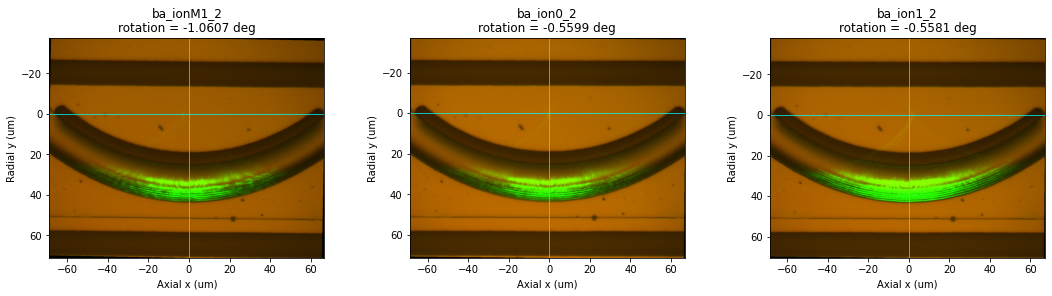

In [8]:
%matplotlib inline
preview_references(datasets, alignments)


## Process all datasets
Frames are read one at a time. Processed caches are invalidated when source files, the independent alignment, thresholds, or dark calibration change.

In [9]:
missing = set(datasets) - set(alignments)
if missing:
    raise RuntimeError(f"Complete the independent alignment cell first for ions {sorted(missing)}")
results = {}
for ion, dataset in datasets.items():
    results[ion] = process_dataset(dataset, alignments[ion], dark,
        min_signal=MIN_SIGNAL, max_rgb=MAX_RGB_CHANNEL, cache_dir=CACHE_DIR,
        excluded_exposures_ms=EXCLUDED_EXPOSURES_MS.get(ion, ()))

hdr_summary_all = pd.concat([r["summary"].assign(ion=ion, dataset=r["dataset"]["name"])
                            for ion, r in results.items()], ignore_index=True)
saturation_all = pd.concat([r["saturation"].assign(ion=ion, dataset=r["dataset"]["name"])
                            for ion, r in results.items()], ignore_index=True)
hdr_summary_all.to_csv(OUTPUT_DIR / "hdr_peak_summary.csv", index=False)
saturation_all.to_csv(OUTPUT_DIR / "short_exposure_saturation.csv", index=False)
display(hdr_summary_all.groupby(["ion", "dataset"]).agg(
    heights=("height_um", "size"), peaks_using_0p2_ms=("peak_uses_0p2_ms", "sum"),
    peak_rate_min=("peak_rate_counts_s", "min"), peak_rate_max=("peak_rate_counts_s", "max")))
display(saturation_all.groupby(["ion", "dataset"])["all_channels_below_sat"].all())


ba_ionM1_2: 1/21 heights
ba_ionM1_2: 5/21 heights
ba_ionM1_2: 10/21 heights
ba_ionM1_2: 15/21 heights
ba_ionM1_2: 20/21 heights
ba_ionM1_2: 21/21 heights
ba_ion0_2: 1/21 heights
ba_ion0_2: 5/21 heights
ba_ion0_2: 10/21 heights
ba_ion0_2: 15/21 heights
ba_ion0_2: 20/21 heights
ba_ion0_2: 21/21 heights
ba_ion1_2: 1/21 heights
ba_ion1_2: 5/21 heights
ba_ion1_2: 10/21 heights
ba_ion1_2: 15/21 heights
ba_ion1_2: 20/21 heights
ba_ion1_2: 21/21 heights


,,heights,peaks_using_0p2_ms,peak_rate_min,peak_rate_max
ion,dataset,,,,
-1,ba_ionM1_2,21,21,335641.68750,8.816856e+05
0,ba_ion0_2,21,21,385737.46875,9.418006e+05
1,ba_ion1_2,21,21,536024.81250,1.097098e+06


ion  dataset   
-1   ba_ionM1_2     True
 0   ba_ion0_2      True
 1   ba_ion1_2     False
Name: all_channels_below_sat, dtype: bool

## HDR images, axial cuts, and exposure maps
The same exposure color is used across heights within each dataset. Set `PLOT_HEIGHTS_UM = None` to display all heights.

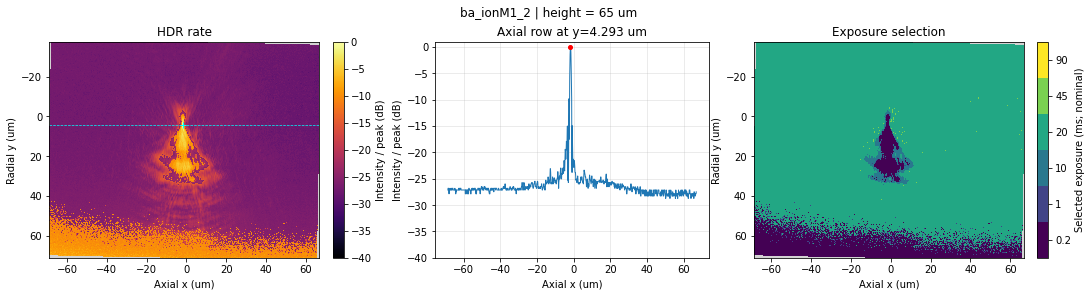

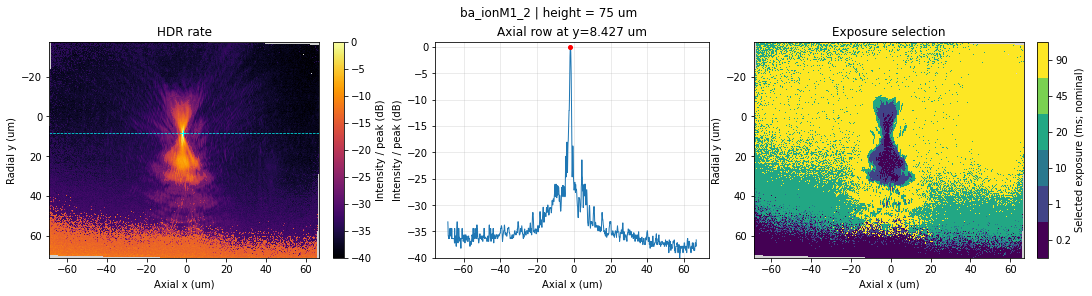

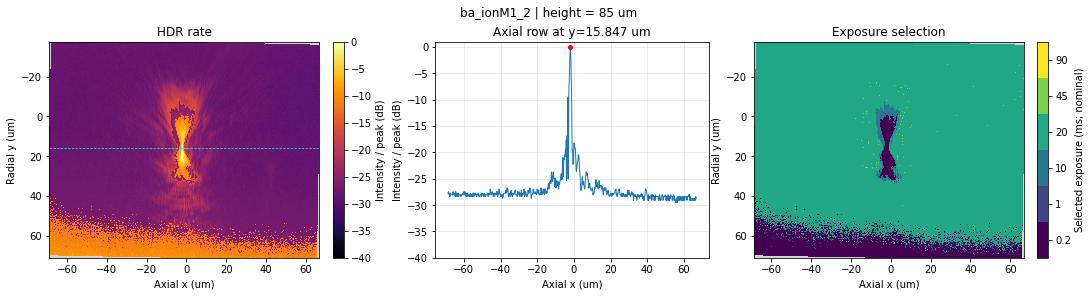

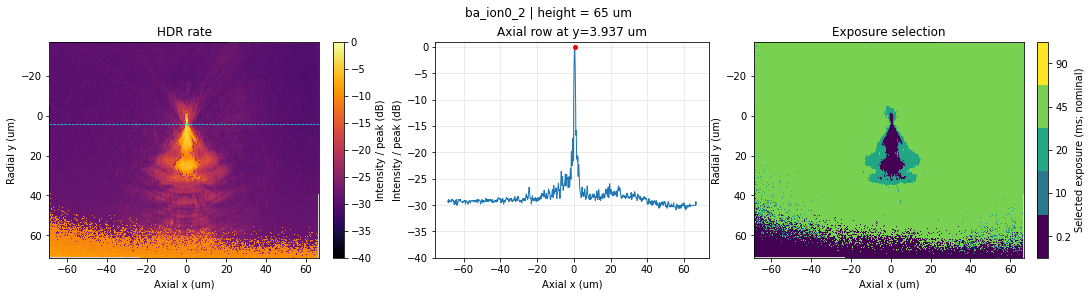

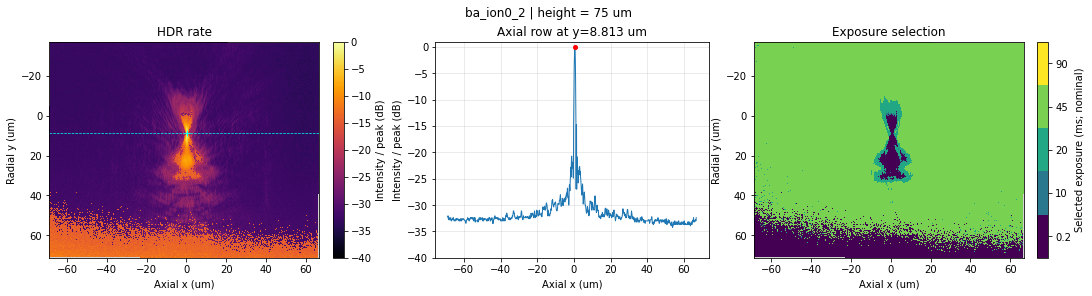

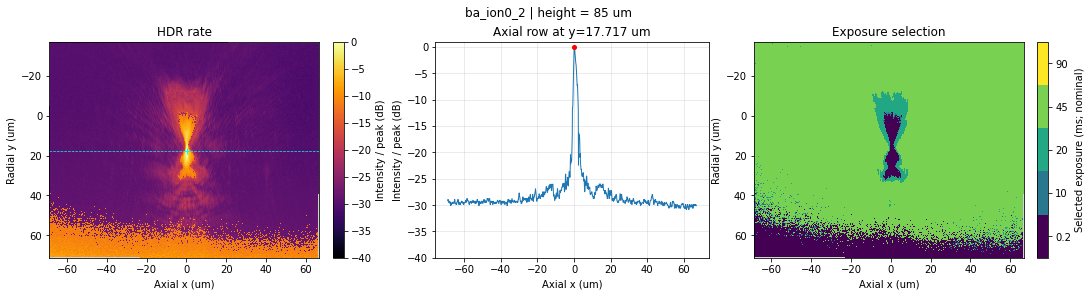

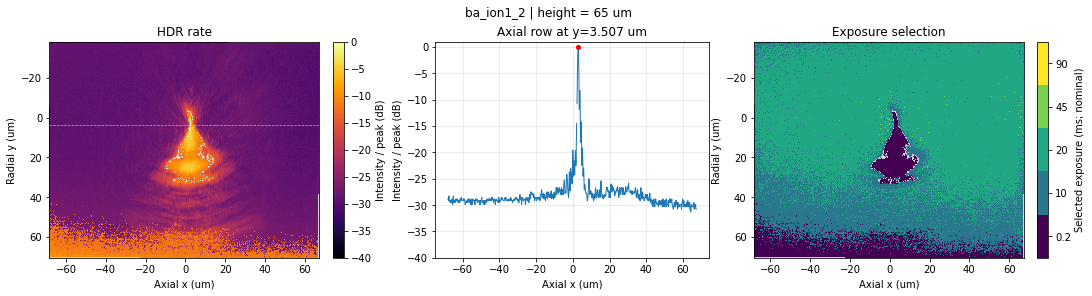

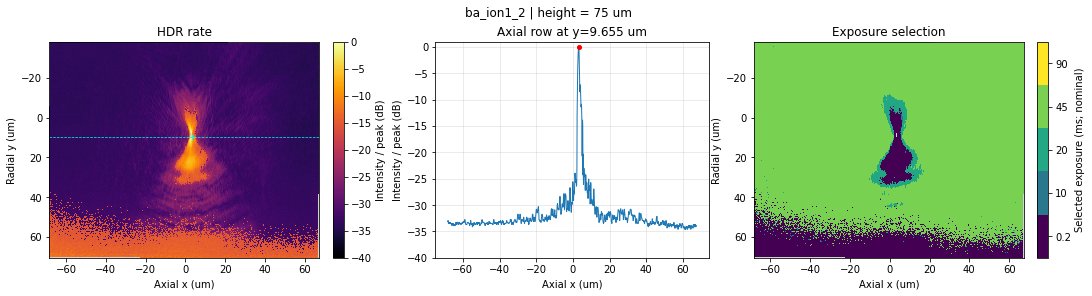

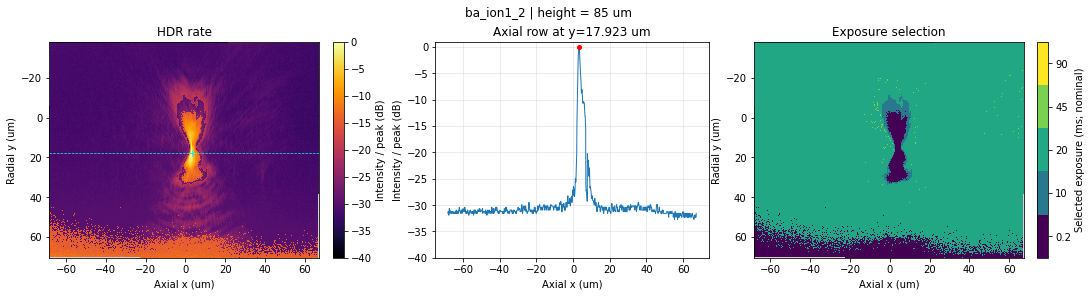

In [10]:
for ion, result in results.items():
    plot_hdr(result, PLOT_HEIGHTS_UM, db_floor=DB_FLOOR)


## Crosstalk at ±5 µm versus height
With `CROSSTALK_Y_UM = None`, each height uses one axial row through its brightest pixel. Both offsets are measured from that row’s peak and normalized to it.

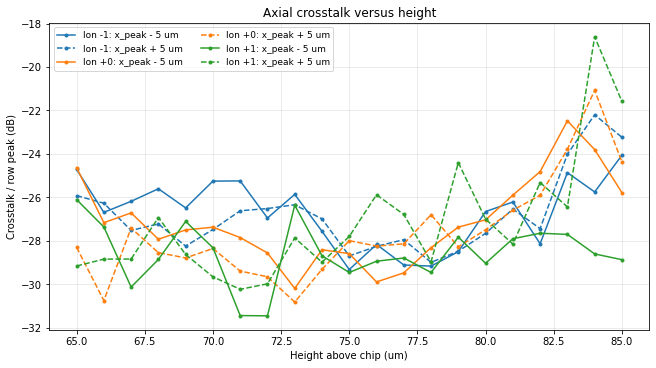

,height_um,peak_x_um,sample_y_um,peak_rate_counts_s,sample_x_minus_um,crosstalk_minus_db,sample_x_plus_um,crosstalk_plus_db,ion
0,65.0,-1.746341,4.293077,335641.68750,-6.746341,-24.712779,3.253659,-25.921411,-1
1,66.0,-1.746341,4.187077,390747.06250,-6.746341,-26.692117,3.253659,-26.271482,-1
2,67.0,-1.852341,4.823077,445852.40625,-6.852341,-26.182607,3.147659,-27.522782,-1
3,68.0,-1.746341,4.929077,505967.34375,-6.746341,-25.606368,3.253659,-27.225353,-1
4,69.0,-1.746341,5.671077,536024.81250,-6.746341,-26.486319,3.253659,-28.244922,-1
...,...,...,...,...,...,...,...,...,...
58,81.0,3.330903,11.456602,936791.00000,-1.669097,-27.903929,8.330903,-28.151054,1
59,82.0,3.224903,11.774602,781494.12500,-1.775097,-27.653925,8.224903,-25.317878,1
60,83.0,3.330903,12.728602,696331.31250,-1.669097,-27.705091,8.330903,-26.440719,1
61,84.0,3.012903,18.134602,761455.81250,-1.987097,-28.604560,8.012903,-18.608458,1


In [11]:
crosstalk_tables = {ion: crosstalk_by_height(result, CROSSTALK_OFFSET_UM, CROSSTALK_Y_UM)
                    for ion, result in results.items()}
crosstalk_all = pd.concat([table.assign(ion=ion) for ion, table in crosstalk_tables.items()],
                          ignore_index=True)
crosstalk_all.to_csv(OUTPUT_DIR / "axial_offset_crosstalk.csv", index=False)
plot_crosstalk_scan(crosstalk_tables, CROSSTALK_OFFSET_UM)
display(crosstalk_all)


## Neighboring-ion crosstalk matrix
Rows are **measured-ion locations**, columns are **driven ions**. Every column uses only its own driven dataset and its own brightest-pixel axial row. For driven ion i, evaluate the nearest measured pixel to x_peak + (j−i) × 5 µm and normalize to that same driven peak. No position from another dataset is used.

For ion −1, the off-diagonal offsets are +5/+10 µm; for ion 0, −5/+5 µm; for ion +1, −5/−10 µm. At 75 µm these six entries must match the reference values in the six crosstalk maps. Diagonal entries are 0 dB, and missing samples remain N/A.

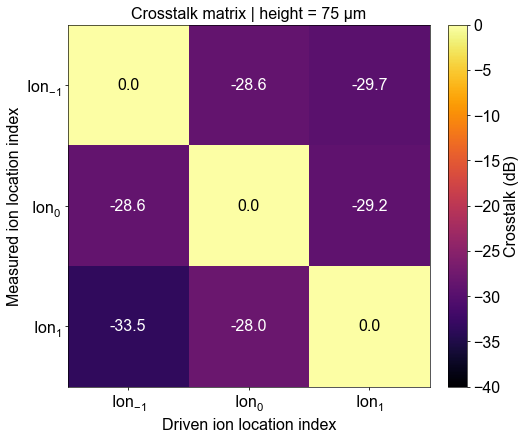

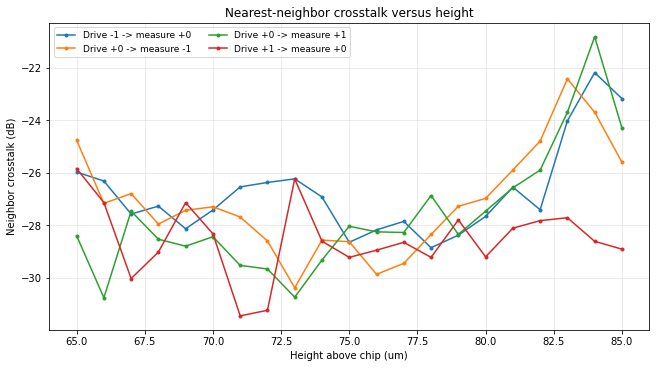

driven_ion,-1,0,1
measured_ion,,,
-1,0.000000,-28.618726,-29.679384
0,-28.640062,0.000000,-29.214885
1,-33.508790,-28.030467,0.000000


ion,-1,0,1
height_um,,,
65.0,-1.746341,0.477574,2.906903
66.0,-1.746341,0.371574,2.906903
67.0,-1.852341,0.371574,2.906903
68.0,-1.746341,0.371574,3.012903
69.0,-1.746341,0.371574,3.012903
70.0,-1.746341,0.477574,3.118903
71.0,-1.746341,0.371574,3.012903
72.0,-1.746341,0.477574,3.118903
73.0,-1.746341,0.477574,3.118903


In [12]:
# Each column uses ONLY its driven dataset: own peak, own radial row, own normalization.
# Sample offsets (measured_ion - driven_ion) * 5 um, using nearest measured pixels.
neighbor_scan = neighboring_matrices(results, y_um=None, pitch_um=ION_PITCH_UM)
if neighbor_scan["mode"] != "driven_peak_nearest_pixel":
    raise RuntimeError("Rerun the HDR/axial-sampling/matrix function cell before this matrix cell.")
neighbor_scan["table"].to_csv(OUTPUT_DIR / "neighbor_crosstalk_all_heights.csv", index=False)
neighbor_scan["peak_positions"].to_csv(OUTPUT_DIR / "neighbor_peak_positions.csv", index=False)
plot_neighbor_matrix(neighbor_scan, MATRIX_HEIGHT_UM, DB_FLOOR,
                     font_family="Arial", font_size=16)
plot_neighbor_scan(neighbor_scan)
selected = neighbor_scan["table"][np.isclose(neighbor_scan["table"].height_um,
                                            MATRIX_HEIGHT_UM, rtol=0, atol=1e-4)]
display(selected.pivot(index="measured_ion", columns="driven_ion", values="crosstalk_db"))
display(neighbor_scan["peak_positions"].pivot(index="height_um", columns="ion", values="peak_x_um"))


## Matrices at all common heights

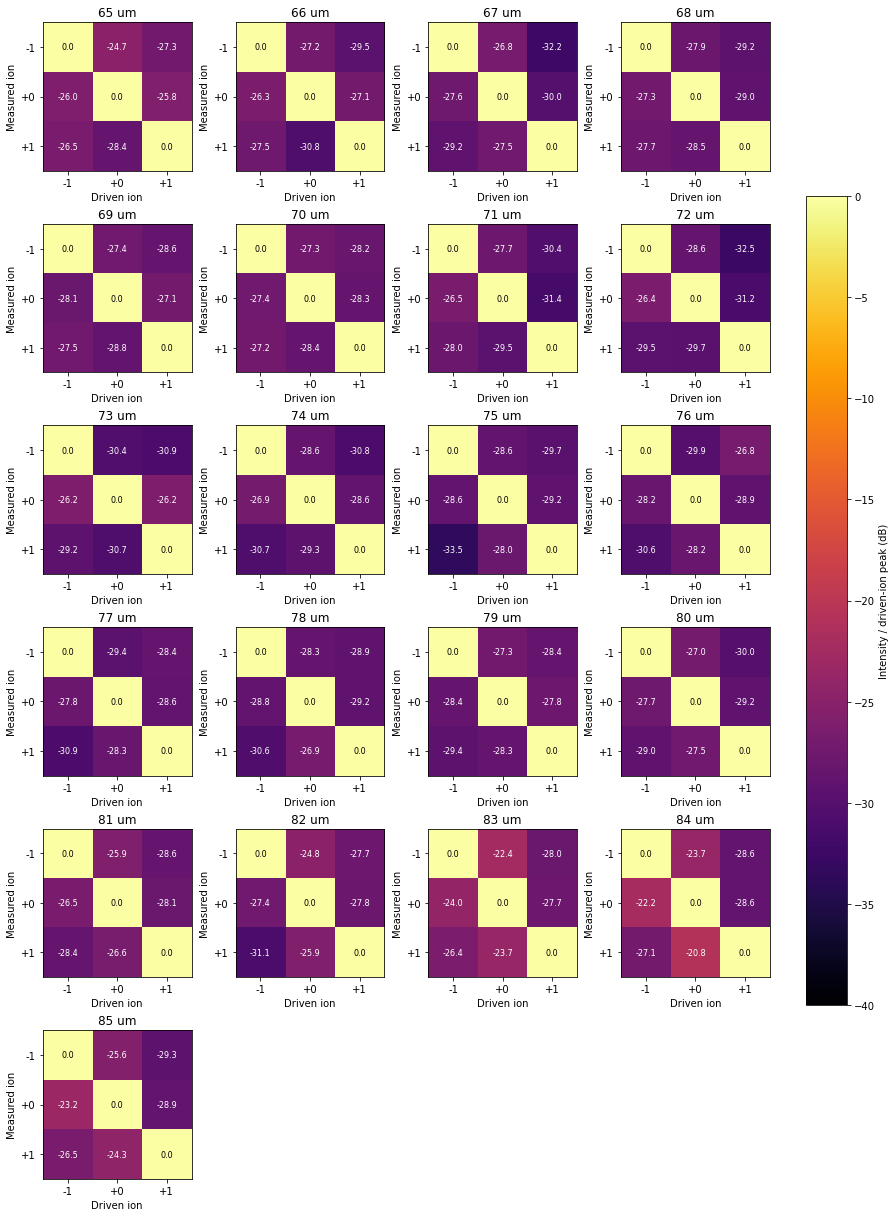

In [13]:
plot_matrix_grid(neighbor_scan, db_floor=DB_FLOOR)


## Publication analysis: reference at 75 µm
For each independently aligned ion, locate the brightest valid 2-D HDR pixel at 75 µm. Its radial coordinate defines Δy = 0. Sample heights from 65 to 85 µm in 1 µm steps and radial offsets from −5 to +5 µm in 1 µm steps around y₀.

At every (h, y), find the axial maximum xₚ(h, y), then calculate

$$C_{\Delta x}(h,y)=10\log_{10}\!\left[\frac{I_{\mathrm{HDR}}(x_p(h,y)+\Delta x,y,h)}{I_{\mathrm{HDR}}(x_p(h,y),y,h)}\right].$$

Offsets are +5/+10 µm for ion −1; −5/+5 µm for ion 0; and −5/−10 µm for ion +1. This gives two maps per ion. For each nominal 1 µm radial and height target, select the closest measured row and height plane. Find the axial peak on that measured row, then select the closest measured axial pixel at each requested neighbor offset. No interpolation or smoothing is applied. Requested coordinates and actual sampled coordinates are both recorded; invalid sampled pixels remain missing.

In [14]:
publication_scan = analyze_reference_windows(
    results, PUBLICATION_OFFSETS_UM,
    reference_height_um=PUBLICATION_REFERENCE_HEIGHT_UM,
    height_half_range_um=PUBLICATION_HEIGHT_HALF_RANGE_UM,
    radial_half_range_um=PUBLICATION_RADIAL_HALF_RANGE_UM,
    radial_step_um=PUBLICATION_RADIAL_STEP_UM,
    height_step_um=PUBLICATION_HEIGHT_STEP_UM,
    peak_search_half_width_um=PUBLICATION_PEAK_SEARCH_HALF_WIDTH_UM,
)
publication_scan["settings"]["dark_calibration_path"] = str(DARK_PATH)
publication_scan["settings"]["dark_calibration_sha256"] = hashlib.sha256(DARK_PATH.read_bytes()).hexdigest()
publication_scan["settings"]["uncertainty_note"] = (
    "Point estimates only: one signal frame per exposure/height; saved dark calibration contains spatial means, not variances."
)
publication_quality = export_reference_windows(
    publication_scan, results, PUBLICATION_DIR, PUBLICATION_DB_LIMITS)
display(publication_scan["anchors"])
display(publication_scan["baseline"])
display(publication_quality)


,ion,dataset,reference_height_um,peak_x_um,peak_y_um,reference_peak_counts_s,reference_exposure_ms,reference_nominal_exposure_ms,native_radial_step_um,radial_samples,radial_sample_step_um,height_sample_step_um
0,-1,ba_ionM1_2,75.0,-1.852341,8.427077,8.315899e+05,0.199618,0.2,0.106,11,1.0,1.0
1,0,ba_ion0_2,75.0,0.477574,8.813408,8.917048e+05,0.199618,0.2,0.106,11,1.0,1.0
2,1,ba_ion1_2,75.0,3.118903,9.654602,1.097098e+06,0.199618,0.2,0.106,11,1.0,1.0


,ion,offset_um,height_um,peak_x_um,peak_y_um,target_x_um,sample_x_um,actual_offset_um,central_rate_counts_s,neighbor_rate_counts_s,crosstalk_linear,crosstalk_db
0,-1,5.0,75.0,-1.852341,8.427077,3.147659,3.129659,4.982,8.315899e+05,1137.373169,0.001368,-28.640062
1,-1,10.0,75.0,-1.852341,8.427077,8.147659,8.111659,9.964,8.315899e+05,370.706512,0.000446,-33.508790
2,0,-5.0,75.0,0.477574,8.813408,-4.522426,-4.504426,-4.982,8.917048e+05,1225.599243,0.001374,-28.618726
3,0,5.0,75.0,0.477574,8.813408,5.477574,5.459574,4.982,8.917048e+05,1403.377075,0.001574,-28.030467
4,1,-5.0,75.0,3.118903,9.654602,-1.881097,-1.863097,-4.982,1.097098e+06,1314.488159,0.001198,-29.214885
5,1,-10.0,75.0,3.118903,9.654602,-6.881097,-6.845097,-9.964,1.097098e+06,1181.154785,0.001077,-29.679384


,ion,offset_um,valid_samples,total_samples,valid_fraction,min_db,max_db,max_abs_peak_shift_um,samples_below_color_min,samples_above_color_max
0,-1,5.0,231,231,1.0,-29.275280,-8.670924,1.166,0,0
1,-1,10.0,231,231,1.0,-33.508790,-15.002290,1.166,0,0
2,0,-5.0,231,231,1.0,-31.233323,-7.145244,1.378,0,0
3,0,5.0,231,231,1.0,-30.705504,-5.862657,1.378,0,0
4,1,-5.0,231,231,1.0,-32.550384,-10.370433,2.438,0,0
5,1,-10.0,231,231,1.0,-34.256336,-19.043418,2.438,0,0


## Publication figures
Three reference axial slices and six height–radial crosstalk maps. The white, labeled contour marks −20 dB. Sampling remains on the nominal 1 µm grid; axes use normal tick spacing. All maps share the same dB limits, gray indicates an invalid sample, and the open circle marks the 75 µm reference. Figures are displayed inline only.

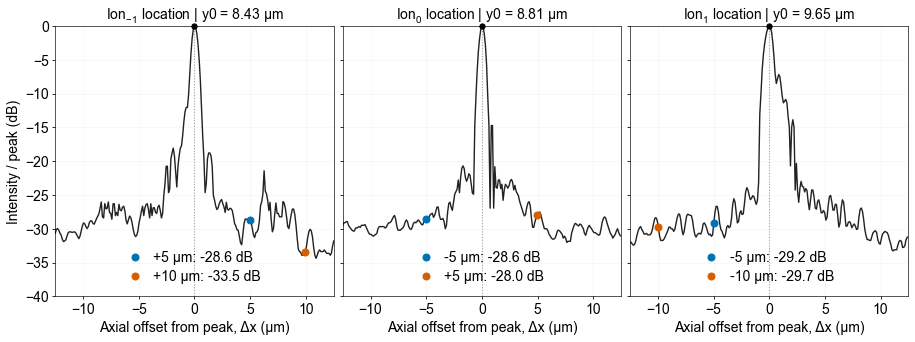

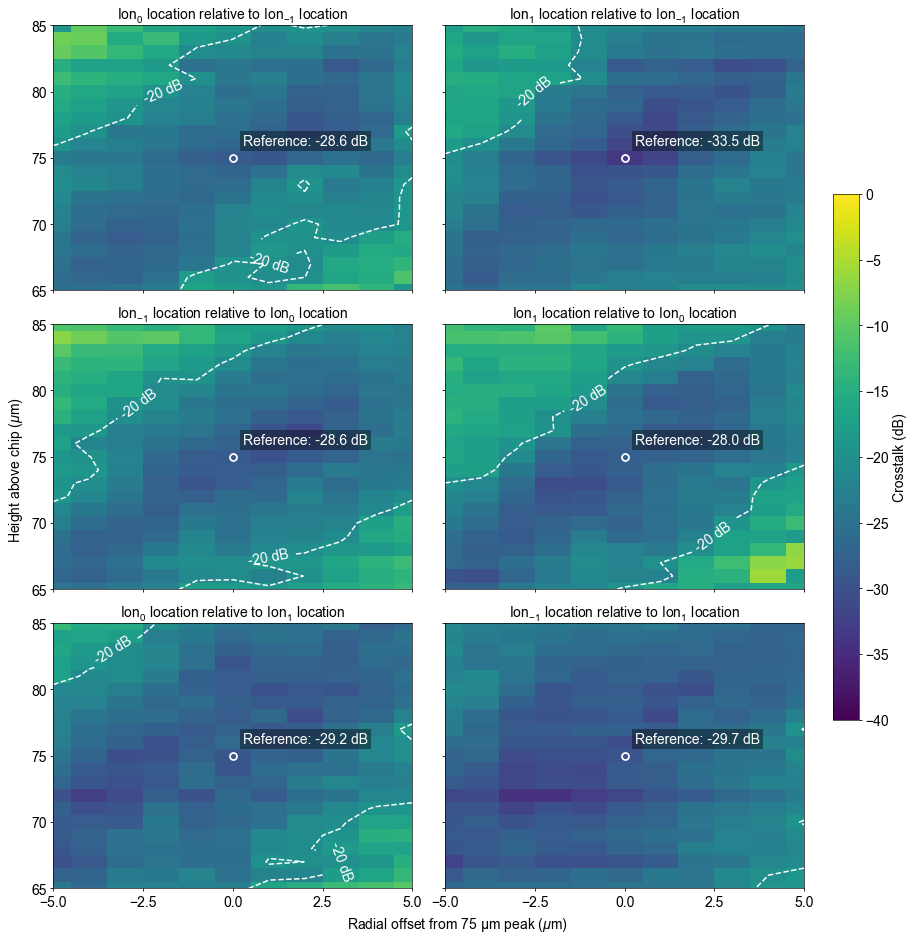

In [15]:
# Nearest-pixel sampling remains on a nominal 1 um radial and height grid.
# Axis tick spacing is independent of sampling; use normal ticks here.
PUBLICATION_DB_LIMITS = (-40.0, 0.0)
plot_reference_axial_profiles(publication_scan, db_limits=PUBLICATION_DB_LIMITS,
                              font_family="Arial", font_size=14)
plot_height_radial_maps(publication_scan, color_limits_db=PUBLICATION_DB_LIMITS,
                       contour_db=-20.0, font_family="Arial", font_size=14)


## Publication overlay — all three channels at one radial cut
Choose `COMMON_SLICE_Y_UM` below. Each channel uses the nearest measured radial row at the same height and is normalized to its own peak on that slice. The plot retains the independently aligned trench coordinates, shows measured adjacent peak separations, and uses Arial 18 pt labels with a −35 to 0 dB range. The next cell reports all six directed crosstalk values at the other measured peak locations and a 3×3 table. SVG export is separate.


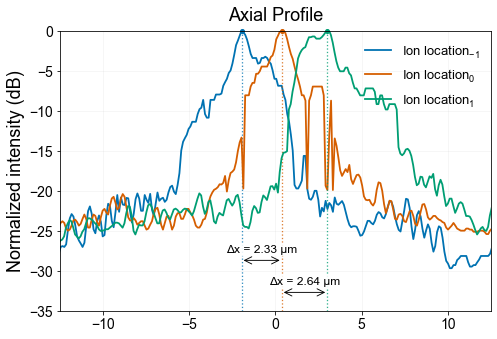

,ion,height_um,requested_y_um,sampled_y_um,slice_peak_x_um,slice_peak_rate_counts_s
0,-1,75.0,14.0,14.045077,-1.958341,220421.406250
1,0,75.0,14.0,14.007408,0.371574,225430.984375
2,1,75.0,14.0,14.000602,3.012903,290555.500000


,left_ion,right_ion,left_peak_x_um,right_peak_x_um,separation_um
0,-1,0,-1.958341,0.371574,2.329916
1,-1,1,-1.958341,3.012903,4.971245
2,0,1,0.371574,3.012903,2.641329


In [25]:
# Overlay all three measured profiles on their existing trench-referenced axes.
# No peak recentering, imposed ion pitch, or cross-dataset registration is applied.
COMMON_SLICE_Y_UM = 14.0  # Common radial cut; adjust for all three channels together.
COMMON_SLICE_HEIGHT_UM = PUBLICATION_REFERENCE_HEIGHT_UM
COMMON_SLICE_X_LIMITS_UM = (-12.5, 12.5)
COMMON_SLICE_DB_LIMITS = (-35.0, 0.0)
COMMON_SLICE_FONT_SIZE = 18
COMMON_SLICE_TITLE = "Axial Profile"
COMMON_SLICE_SEPARATION_Y_DB = (-28.7, -32.7)  # Stagger the two adjacent-pair labels.

if "results" not in globals():
    raise RuntimeError("Run HDR processing after alignment before plotting the common cut.")
if set(results) != {-1, 0, 1}:
    raise ValueError("This comparison requires the three driven channels: -1, 0, and +1.")

common_slice_profiles = {}
common_slice_records = []
for ion, result in sorted(results.items()):
    slot = height_slot(result, COMMON_SLICE_HEIGHT_UM)
    profile, peak_x, sampled_y, peak_rate = axial_profile(
        result, slot, y_um=COMMON_SLICE_Y_UM,
    )
    if not np.isfinite(peak_rate) or peak_rate <= 0:
        raise ValueError(f"Ion {ion}: no valid signal on the selected radial slice.")
    x = result["x_um"]
    if not COMMON_SLICE_X_LIMITS_UM[0] <= peak_x <= COMMON_SLICE_X_LIMITS_UM[1]:
        raise ValueError(f"Ion {ion}: expand COMMON_SLICE_X_LIMITS_UM to include its peak.")
    db = np.full(profile.shape, np.nan)
    valid = np.isfinite(profile) & (profile > 0)
    db[valid] = 10*np.log10(profile[valid]/peak_rate)
    common_slice_profiles[ion] = dict(x_um=x, db=db, peak_x_um=peak_x)
    common_slice_records.append(dict(
        ion=ion, height_um=COMMON_SLICE_HEIGHT_UM,
        requested_y_um=COMMON_SLICE_Y_UM, sampled_y_um=sampled_y,
        slice_peak_x_um=peak_x, slice_peak_rate_counts_s=peak_rate,
    ))

common_slice_table = pd.DataFrame(common_slice_records)
# Record every pair's measured separation; no nominal pitch is imposed.
ordered_ions = sorted(common_slice_profiles, key=lambda ion: common_slice_profiles[ion]["peak_x_um"])
common_slice_separation_table = pd.DataFrame([
    dict(left_ion=left, right_ion=right,
         left_peak_x_um=common_slice_profiles[left]["peak_x_um"],
         right_peak_x_um=common_slice_profiles[right]["peak_x_um"],
         separation_um=abs(common_slice_profiles[right]["peak_x_um"]-common_slice_profiles[left]["peak_x_um"]))
    for index, left in enumerate(ordered_ions) for right in ordered_ions[index+1:]
])
with plt.rc_context({
    "font.family": "Arial", "font.size": COMMON_SLICE_FONT_SIZE,
    "axes.labelsize": COMMON_SLICE_FONT_SIZE,
    "xtick.labelsize": 14, "ytick.labelsize": 14,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": "black", "axes.labelcolor": "black",
    "axes.edgecolor": "black", "xtick.color": "black", "ytick.color": "black",
    "svg.fonttype": "none",
    "mathtext.fontset": "custom", "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold",
}):
    if "common_slice_figure" in globals():
        plt.close(common_slice_figure)
    common_slice_figure, ax = plt.subplots(figsize=(6.8, 4.6), constrained_layout=True)
    for ion, color, style in ((-1, "#0072B2", "-"), (0, "#D55E00", "-"), (1, "#009E73", "-")):
        profile = common_slice_profiles[ion]
        ax.plot(profile["x_um"], profile["db"], color=color, ls=style, lw=1.8,
                label=rf"Ion location$_{{{ion}}}$")
        ax.axvline(profile["peak_x_um"], color=color, ls=":", lw=1.3, alpha=0.8)
        ax.plot(profile["peak_x_um"], 0, "o", color=color, ms=4, clip_on=False)
    for index, (left, right) in enumerate(zip(ordered_ions[:-1], ordered_ions[1:])):
        left_peak = common_slice_profiles[left]["peak_x_um"]
        right_peak = common_slice_profiles[right]["peak_x_um"]
        arrow_y = COMMON_SLICE_SEPARATION_Y_DB[index]
        ax.annotate("", xy=(left_peak, arrow_y), xytext=(right_peak, arrow_y),
                    arrowprops=dict(arrowstyle="<->", color="black", lw=0.9))
        ax.text((left_peak+right_peak)/2, arrow_y+0.7, f"Δx = {right_peak-left_peak:.2f} µm",
                ha="center", va="bottom", fontsize=12,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.9, pad=1.5))
    ax.set(xlim=COMMON_SLICE_X_LIMITS_UM, ylim=COMMON_SLICE_DB_LIMITS,
           xticks=[-10, -5, 0, 5, 10], yticks=np.arange(-35, 1, 5),
           xlabel="", ylabel="Normalized intensity (dB)")
    ax.set_title(
        COMMON_SLICE_TITLE,
        fontfamily="Arial", fontsize=18, pad=10,
    )
    ax.grid(alpha=0.18, lw=0.6)
    ax.legend(frameon=False, fontsize=13, loc="upper right")
    display(common_slice_figure)
    plt.close(common_slice_figure)

# The nearest measured rows can differ by a fraction of a camera pixel.
# Separation is in the existing independently selected trench coordinate frames.
display(common_slice_table)
display(common_slice_separation_table)


In [17]:
# All six directed crosstalk values at the other two measured beam locations.
# Use the nearest measured axial pixel, preserving invalid samples as NaN.
# Normalize to the driven beam's own slice peak; these are not fixed ±5 µm samples.
if "common_slice_profiles" not in globals() or "common_slice_table" not in globals():
    raise RuntimeError("Run the common-y overlay cell above first.")
common_slice_crosstalk_records = []
for driven, measured in ((d, m) for d in sorted(common_slice_profiles)
                         for m in sorted(common_slice_profiles) if m != d):
    profile = common_slice_profiles[driven]
    target_x = common_slice_profiles[measured]["peak_x_um"]
    x = profile["x_um"]
    value_db, sampled_x = np.nan, np.nan
    if x[0] <= target_x <= x[-1]:
        index = int(np.argmin(np.abs(x-target_x)))
        sampled_x = float(x[index])
        value_db = float(profile["db"][index])
    metadata = common_slice_table.loc[common_slice_table.ion == driven].iloc[0]
    ratio = 10**(value_db/10) if np.isfinite(value_db) else np.nan
    common_slice_crosstalk_records.append(dict(
        driven_ion=driven, measured_location=measured,
        height_um=float(metadata.height_um),
        requested_y_um=float(metadata.requested_y_um), sampled_y_um=float(metadata.sampled_y_um),
        driven_peak_x_um=profile["peak_x_um"], target_peak_x_um=target_x,
        sampled_x_um=sampled_x, actual_offset_um=sampled_x-profile["peak_x_um"],
        crosstalk_db=value_db, intensity_ratio=ratio, intensity_percent=100*ratio,
    ))
common_slice_crosstalk_table = pd.DataFrame(common_slice_crosstalk_records)
# Rows are measured locations; columns are driven channels. Each column uses
# the corresponding driven beam's own peak on the common slice as its reference.
common_slice_crosstalk_matrix_db = common_slice_crosstalk_table.pivot(
    index="measured_location", columns="driven_ion", values="crosstalk_db",
).reindex(index=sorted(common_slice_profiles), columns=sorted(common_slice_profiles))
for ion in common_slice_profiles:
    common_slice_crosstalk_matrix_db.loc[ion, ion] = 0.0
display(common_slice_crosstalk_matrix_db)
display(common_slice_crosstalk_table)
for point in common_slice_crosstalk_table.itertuples(index=False):
    print(f"Drive ion {point.driven_ion} → ion {point.measured_location} location "
          f"(x = {point.target_peak_x_um:.3f} µm): "
          f"{point.crosstalk_db:.2f} dB ({point.intensity_percent:.3f}%)")


driven_ion,-1,0,1
measured_location,,,
-1,0.000000,-26.944220,-27.429653
0,-19.584091,0.000000,-27.858128
1,-25.554583,-24.865322,0.000000


,driven_ion,measured_location,height_um,requested_y_um,sampled_y_um,driven_peak_x_um,target_peak_x_um,sampled_x_um,actual_offset_um,crosstalk_db,intensity_ratio,intensity_percent
0,-1,0,75.0,10.0,10.017077,-1.746341,0.477574,0.479659,2.226,-19.584091,0.011005,1.100502
1,-1,1,75.0,10.0,10.017077,-1.746341,3.118903,3.129659,4.876,-25.554583,0.002783,0.278318
2,0,-1,75.0,10.0,9.979408,0.477574,-1.746341,-1.748426,-2.226,-26.944220,0.002021,0.202105
3,0,1,75.0,10.0,9.979408,0.477574,3.118903,3.127574,2.650,-24.865322,0.003262,0.326188
4,1,-1,75.0,10.0,9.972602,3.118903,-1.746341,-1.757097,-4.876,-27.429653,0.001807,0.180732
5,1,0,75.0,10.0,9.972602,3.118903,0.477574,0.468903,-2.650,-27.858128,0.001638,0.163752


Drive ion -1 → ion 0 location (x = 0.478 µm): -19.58 dB (1.101%)
Drive ion -1 → ion 1 location (x = 3.119 µm): -25.55 dB (0.278%)
Drive ion 0 → ion -1 location (x = -1.746 µm): -26.94 dB (0.202%)
Drive ion 0 → ion 1 location (x = 3.119 µm): -24.87 dB (0.326%)
Drive ion 1 → ion -1 location (x = -1.746 µm): -27.43 dB (0.181%)
Drive ion 1 → ion 0 location (x = 0.478 µm): -27.86 dB (0.164%)


In [18]:
# SVG only: editable Arial text and the measured, unshifted axial coordinates.
COMMON_SLICE_EXPORT_DIR = OUTPUT_DIR / "publication_common_y"
COMMON_SLICE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
common_slice_svg_path = COMMON_SLICE_EXPORT_DIR / (
    f"ba_axial_profiles_three_channels_y{COMMON_SLICE_Y_UM:g}um_"
    f"h{COMMON_SLICE_HEIGHT_UM:g}um.svg"
)
if "common_slice_figure" not in globals():
    raise RuntimeError("Run the common-y overlay cell above first.")
with plt.rc_context({"svg.fonttype": "none", "svg.image_inline": True,
                     "mathtext.fontset": "custom", "mathtext.rm": "Arial",
                     "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold"}):
    common_slice_figure.savefig(common_slice_svg_path, bbox_inches="tight",
                               facecolor="white", transparent=False)
print(f"Saved: {common_slice_svg_path}")


Saved: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/cross_talk_results/publication_common_y/ba_axial_profiles_three_channels_y10um_h75um.svg


## Export the Ba crosstalk matrix and neighboring crosstalk maps
Run the two plotting-function cells once after this update, then run the export cell. Leave `FIGURE_EXPORT_DIR = None` to enter a destination folder path at the prompt, or set `Path("/your/export/folder")` directly. A blank response cancels.

The cell exports the current **3 × 3 Ba matrix** and **six-panel height–radial map figure**, preserving their existing styling and analysis. Defaults are vector PDF and 600-dpi PNG; formats and DPI can be changed below. File names begin with `ba_` to distinguish these exports from the Ca figures.

In [19]:
# Run this cell when you want to export the two figures.
FIGURE_EXPORT_DIR = '/Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/My Drive/Ming Wu Integrated Photonics Group/Paper/Gen1_Photonics/Figures/SUPP/Crosstalk_tolerance/ba'       # Or Path("/full/path/to/export/folder")
FIGURE_EXPORT_FORMATS = ("svg","svg")  # Optional: ("svg",)
FIGURE_EXPORT_DPI = 600

if "neighbor_scan" not in globals() or "publication_scan" not in globals():
    raise RuntimeError("Run the matrix and publication-analysis cells before exporting.")
if "export_focus_crosstalk_figures" not in globals():
    raise RuntimeError("Rerun the two plotting-function cells near the top before exporting.")

export_directory_text = (input("Export folder (full path; leave blank to cancel): ").strip()
                         if FIGURE_EXPORT_DIR is None else str(FIGURE_EXPORT_DIR).strip())
if not export_directory_text:
    print("Export cancelled; no files written.")
else:
    exported_figure_paths = export_focus_crosstalk_figures(
        neighbor_scan, publication_scan, Path(export_directory_text).expanduser(),
        matrix_height_um=MATRIX_HEIGHT_UM, db_floor=DB_FLOOR,
        color_limits_db=PUBLICATION_DB_LIMITS, contour_db=-20.0,
        formats=FIGURE_EXPORT_FORMATS, dpi=FIGURE_EXPORT_DPI,
    )
    for exported_figure_path in exported_figure_paths:
        print(f"Saved: {exported_figure_path}")


Saved: /Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/My Drive/Ming Wu Integrated Photonics Group/Paper/Gen1_Photonics/Figures/SUPP/Crosstalk_tolerance/ba/ba_crosstalk_matrix_at_focus.svg
Saved: /Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/My Drive/Ming Wu Integrated Photonics Group/Paper/Gen1_Photonics/Figures/SUPP/Crosstalk_tolerance/ba/ba_crosstalk_height_radial_maps.svg


## Analysis diagnostics
The peak-tracking maps show the chosen axial center at every sample. Exposure-consistency curves show only retained, unsaturated exposures; a single retained point cannot establish exposure linearity.

Nominal **1 ms signal frames are excluded for ions 0 and +1**, following the measured rate discrepancy at their reference peak pixels. Ion −1 is unchanged. The original four-TIFF audit is retained as the reason for this exclusion. The maps and all downstream results use only the included exposures. These are point estimates with no measured uncertainty intervals.

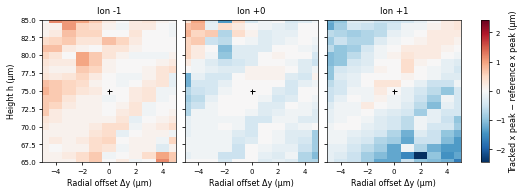

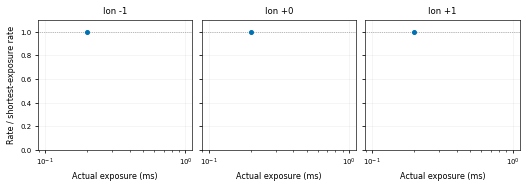

,ion,requested_exposure_ms,actual_exposure_ms,rate_counts_s,rate_relative_to_shortest,passes_thresholds,selected_at_peak
0,-1,0.2,0.199618,8.315899e+05,1.000000,True,True
1,-1,1.0,0.999775,3.690830e+05,0.443828,False,False
2,-1,10.0,10.000000,3.720000e+04,0.044734,False,False
3,-1,20.0,20.000000,3.825000e+04,0.045996,False,False
4,-1,45.0,45.000000,1.675893e+04,0.020153,False,False
5,-1,90.0,90.000000,7.915151e+03,0.009518,False,False
6,0,0.2,0.199618,8.917048e+05,1.000000,True,True
7,0,10.0,10.000000,3.940000e+04,0.044185,False,False
8,0,20.0,20.000000,3.825000e+04,0.042895,False,False
9,0,45.0,45.000000,1.675893e+04,0.018794,False,False


Data tables, arrays, and analysis settings saved to: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/cross_talk_results/publication_75um


In [20]:
# Diagnostics do not modify the requested peak-following calculation.
plot_peak_tracking_diagnostic(publication_scan)
publication_exposure_check = reference_exposure_diagnostic(
    results, PUBLICATION_REFERENCE_HEIGHT_UM, PUBLICATION_DIR)
display(publication_exposure_check[["ion", "requested_exposure_ms", "actual_exposure_ms",
    "rate_counts_s", "rate_relative_to_shortest", "passes_thresholds", "selected_at_peak"]])
print(f"Data tables, arrays, and analysis settings saved to: {PUBLICATION_DIR}")
